In [1]:
# ============================================================
# 0. 导入包并读取原始数据
# ============================================================
# pandas：用于表格数据清洗、合并和聚合
# numpy：用于数值计算以及缺失值处理
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)

# 保留原项目的文件夹结构：notebooks/ 与 data/、outputs/ 同级
RAW_DATA_DIR = "../data/raw"
PROCESSED_DATA_DIR = "../data/processed"
OUTPUT_TABLE_DIR = "../outputs/tables"

# 如果输出文件夹不存在则自动创建，避免 to_csv 时报错
os.makedirs(PROCESSED_DATA_DIR, exist_ok=True)
os.makedirs(OUTPUT_TABLE_DIR, exist_ok=True)

customers = pd.read_csv(f"{RAW_DATA_DIR}/customers.csv")
orders = pd.read_csv(f"{RAW_DATA_DIR}/orders.csv")
orders_items = pd.read_csv(f"{RAW_DATA_DIR}/orders_items.csv")
products = pd.read_csv(f"{RAW_DATA_DIR}/products.csv")
products_skus = pd.read_csv(f"{RAW_DATA_DIR}/products_skus.csv")
traffic = pd.read_csv(f"{RAW_DATA_DIR}/traffic.csv")
transactions = pd.read_csv(f"{RAW_DATA_DIR}/transactions.csv")

print("All raw datasets loaded successfully!")


All raw datasets loaded successfully!


In [2]:
# ============================================================
# 1. 创建清洗副本
# ============================================================
# 不直接修改 raw dataframe，方便后续检查原始数据
customers_clean = customers.copy()
orders_clean = orders.copy()
orders_items_clean = orders_items.copy()
products_clean = products.copy()
products_skus_clean = products_skus.copy()
traffic_clean = traffic.copy()
transactions_clean = transactions.copy()


In [3]:
# ============================================================
# 2. 日期格式清洗
# ============================================================
# errors="coerce"：无法解析的异常日期会变成 NaT，避免程序直接报错
customers_clean["created_at"] = pd.to_datetime(
    customers_clean["created_at"],
    errors="coerce"
)

In [4]:
# 订单表中有多个日期字段，统一转换为 datetime
order_date_columns = [
    "created_at",
    "closed_at",
    "cancelled_at",
    "processed_at"
]

for column in order_date_columns:
    orders_clean[column] = pd.to_datetime(
        orders_clean[column],
        errors="coerce"
    )


In [5]:
# 商品表日期字段
products_clean["created_at"] = pd.to_datetime(
    products_clean["created_at"],
    errors="coerce"
)

products_clean["published_at"] = pd.to_datetime(
    products_clean["published_at"],
    errors="coerce"
)

In [6]:
# SKU 表日期字段
products_skus_clean["created_at"] = pd.to_datetime(
    products_skus_clean["created_at"],
    errors="coerce"
)


In [7]:
# transaction 的时间用于后续检查支付/退款发生顺序
transactions_clean["created_at"] = pd.to_datetime(
    transactions_clean["created_at"],
    errors="coerce"
)


In [8]:
# ============================================================
# 3. 基础数据清洗
# ============================================================
# traffic 中的 index 只是导出 CSV 时产生的旧索引，不是分析变量
traffic_clean = traffic_clean.drop(
    columns=["index"],
    errors="ignore"
)


In [9]:
# 客户姓名缺失不会影响 customer_id 分析，用统一文本填充方便展示
customers_clean["full_name"] = (
    customers_clean["full_name"]
    .fillna("Unknown Customer")
)


In [10]:
# ============================================================
# 商品类型清洗：缺失值、空格、大小写和明显拼写错误
# ============================================================
# 原始 product_type 中存在同一类别被不同写法拆开的情况，
# 例如 Hooide / hoodie 实际都属于 Hoodie，
# Tousers 实际属于 Trousers。
# 如果不在这里统一，后面的 groupby、Top Product Types 和销量趋势图
# 会把同一个商品类别错误地当成多个类别。

products_clean["product_type"] = (
    products_clean["product_type"]
    .fillna("Unknown")
    .astype(str)
    .str.strip()
)

product_type_mapping = {
    # 明显拼写错误
    "Hooide": "Hoodie",
    "Tousers": "Trousers",

    # 同一类别的大小写 / 格式统一
    "hoodie": "Hoodie",
    "TANK": "Tank",
    "crop top": "Crop Top",
    "romper": "Romper",
    "mini": "Mini",
    "midi": "Midi",
    "maxi": "Maxi",
}

products_clean["product_type"] = (
    products_clean["product_type"]
    .replace(product_type_mapping)
)

# 检查清洗后的商品类别，确认错误类别已经消失
print("Number of product types after cleaning:")
print(products_clean["product_type"].nunique())

print("\nProduct type counts after cleaning:")
print(
    products_clean["product_type"]
    .value_counts()
)

Number of product types after cleaning:
27

Product type counts after cleaning:
product_type
Top          57
Dress        26
Trousers     24
Jacket       16
Skirt        15
Shirts       14
Sweater      12
Blazer       11
Mini         10
Blouse        9
Shorts        8
Jumpsuit      7
Hoodie        7
Unknown       5
Crop Top      5
Tank          4
Bodysuit      3
Cardigan      2
Bomber        2
Romper        2
Pants         2
Gift Card     1
Tunic         1
Pullover      1
Maxi          1
Midi          1
Accessory     1
Name: count, dtype: int64


In [11]:
# fulfillment_status 缺失不等于取消订单，因此先标记为 Unknown
orders_clean["fulfillment_status"] = (
    orders_clean["fulfillment_status"]
    .fillna("Unknown")
)

In [12]:
orders_items_clean["fulfillment_status"] = (
    orders_items_clean["fulfillment_status"]
    .fillna("Unknown")
)

In [13]:
# 删除无法在 orders 表中找到对应 order_id 的孤立商品记录
# 这些记录不能可靠地关联订单状态、客户或收入，因此不进入后续分析
orders_items_clean = orders_items_clean[
    orders_items_clean["order_id"].isin(
        orders_clean["id"]
    )
].copy()


In [14]:
print("Clean order items:", orders_items_clean.shape)

Clean order items: (36822, 10)


Four orphan order-item records were excluded because their related
orders could not be found in the orders dataset.

In [15]:
# ============================================================
# 4. 创建订单状态标记
# ============================================================
# 后续不要反复写 financial_status 条件，统一在这里生成布尔变量
orders_clean["is_cancelled"] = orders_clean["cancelled_at"].notna()
orders_clean["is_paid"] = orders_clean["financial_status"].eq("paid")
orders_clean["is_partially_refunded"] = orders_clean["financial_status"].eq("partially_refunded")
orders_clean["is_fully_refunded"] = orders_clean["financial_status"].eq("refunded")
orders_clean["is_pending"] = orders_clean["financial_status"].eq("pending")
orders_clean["is_voided"] = orders_clean["financial_status"].eq("voided")
orders_clean["is_zero_price"] = orders_clean["total_price"].eq(0)


In [16]:
# 创建日/月/年/星期字段，供趋势分析使用
orders_clean["order_date"] = orders_clean["created_at"].dt.normalize()
orders_clean["order_month"] = orders_clean["created_at"].dt.to_period("M").astype(str)
orders_clean["order_year"] = orders_clean["created_at"].dt.year
orders_clean["order_weekday"] = orders_clean["created_at"].dt.day_name()


In [17]:
# ============================================================
# 5. Transaction 聚合
# ============================================================
# 一个订单可能对应多条 transaction，因此必须先按 order_id 聚合，
# 再和 orders 合并，否则会把一张订单复制成多行。

# 成功退款：只统计 kind=refund 且 status=success
refund_summary = (
    transactions_clean[
        transactions_clean["kind"].eq("refund")
        & transactions_clean["status"].eq("success")
    ]
    .groupby("order_id", as_index=False)
    .agg(
        successful_refund_amount=("amount", "sum"),
        successful_refund_count=("id", "count")
    )
)


In [18]:
# 成功收款：只统计 sale / capture 且 status=success
# authorization 只是授权，不代表钱已经实际收进来，因此不计入 revenue
payment_summary = (
    transactions_clean[
        transactions_clean["kind"].isin(["sale", "capture"])
        & transactions_clean["status"].eq("success")
    ]
    .groupby("order_id", as_index=False)
    .agg(
        successful_payment_amount=("amount", "sum"),
        successful_payment_count=("id", "count")
    )
)


In [19]:
# 数据质量检查：确认是否有订单同时出现成功 sale 和 capture
# 若存在，需要进一步确认是否会造成重复收款统计
successful_payment_kinds = (
    transactions_clean[
        transactions_clean["kind"].isin(["sale", "capture"])
        & transactions_clean["status"].eq("success")
    ]
    .groupby("order_id")["kind"]
    .nunique()
)

print(
    "Orders with multiple successful payment kinds:",
    (successful_payment_kinds > 1).sum()
)


Orders with multiple successful payment kinds: 1


In [20]:
# 找出同时存在成功 sale 和 capture 的订单
multi_payment_order_ids = successful_payment_kinds[
    successful_payment_kinds > 1
].index

multi_payment_order_ids

Index([7679027679], dtype='int64', name='order_id')

In [21]:
transactions_clean[
    transactions_clean["order_id"] == 7679027679
][
    [
        "order_id",
        "id",
        "parent_id",
        "kind",
        "status",
        "amount",
        "created_at"
    ]
].sort_values("created_at")

,order_id,id,parent_id,kind,status,amount,created_at
1295,7679027679,8334783455,NaN,authorization,success,119.83,2016-08-22
1296,7679027679,8334783519,8.334783e+09,capture,success,119.83,2016-08-22
1297,7679027679,8334783583,NaN,sale,pending,79.00,2016-08-22
1695,7679027679,8338265247,8.334784e+09,sale,success,79.00,2016-08-23
1719,7679027679,8338945567,8.334784e+09,refund,success,119.83,2016-08-23
1720,7679027679,8338945631,8.338265e+09,refund,success,79.00,2016-08-23


In [22]:
# 汇总每个订单 transaction 记录的状态数量，用于数据质量检查
transaction_summary = (
    transactions_clean
    .groupby("order_id", as_index=False)
    .agg(
        total_transaction_records=("id", "count"),
        successful_transaction_count=("status", lambda x: x.eq("success").sum()),
        failed_transaction_count=("status", lambda x: x.eq("failure").sum()),
        pending_transaction_count=("status", lambda x: x.eq("pending").sum()),
        error_transaction_count=("status", lambda x: x.eq("error").sum())
    )
)

transaction_summary.head()


,order_id,total_transaction_records,successful_transaction_count,failed_transaction_count,pending_transaction_count,error_transaction_count
0,7675398239,2,2,0,0,0
1,7676331935,3,3,0,0,0
2,7676363167,2,2,0,0,0
3,7676539359,2,2,0,0,0
4,7676549855,2,2,0,0,0


In [23]:
# ============================================================
# 6. 建立订单级分析主表 orders_analysis
# ============================================================
# 目标：最终保持“一行 = 一个订单”
orders_analysis = orders_clean.copy()
print("Before merge:", orders_analysis.shape)


Before merge: (21358, 24)


In [24]:
# 合并客户信息
# validate="many_to_one"：多个订单可以属于同一客户，但 customer id 应唯一
orders_analysis = orders_analysis.merge(
    customers_clean[["id", "full_name", "created_at"]],
    left_on="customer_id",
    right_on="id",
    how="left",
    suffixes=("_order", "_customer"),
    validate="many_to_one"
)

print("After customer merge:", orders_analysis.shape)


After customer merge: (21358, 27)


In [25]:
# 重命名 merge 后容易混淆的 id / created_at
orders_analysis = orders_analysis.rename(
    columns={
        "id_order": "order_id",
        "id_customer": "customer_record_id",
        "created_at_order": "order_created_at",
        "created_at_customer": "customer_created_at"
    }
)


In [26]:
# 合并退款汇总；refund_summary 已经是一行一个 order_id
orders_analysis = orders_analysis.merge(
    refund_summary,
    on="order_id",
    how="left",
    validate="one_to_one"
)

print("After refund merge:", orders_analysis.shape)


After refund merge: (21358, 29)


In [27]:
# 合并 transaction 状态汇总
orders_analysis = orders_analysis.merge(
    transaction_summary,
    on="order_id",
    how="left",
    validate="one_to_one"
)

print("After transaction merge:", orders_analysis.shape)


After transaction merge: (21358, 34)


In [28]:
# 没有对应 transaction/refund 记录的订单填 0
transaction_columns = [
    "successful_refund_amount",
    "successful_refund_count",
    "total_transaction_records",
    "successful_transaction_count",
    "failed_transaction_count",
    "pending_transaction_count",
    "error_transaction_count"
]

orders_analysis[transaction_columns] = (
    orders_analysis[transaction_columns].fillna(0)
)


In [29]:
orders_analysis.shape

(21358, 34)

In [30]:
orders_analysis.head(50)

,order_id,order_created_at,closed_at,cancelled_at,customer_id,financial_status,fulfillment_status,processed_at,total_price,shipping_rate,subtotal_price,total_discounts,total_line_items_price,is_cancelled,is_paid,is_partially_refunded,is_fully_refunded,is_pending,is_voided,is_zero_price,order_date,order_month,order_year,order_weekday,customer_record_id,full_name,customer_created_at,successful_refund_amount,successful_refund_count,total_transaction_records,successful_transaction_count,failed_transaction_count,pending_transaction_count,error_transaction_count
0,7675398239,2016-08-21,2016-08-25,2016-08-22,8683754719,voided,Unknown,2016-08-21,44.57,6.33,35.0,0.0,35.0,True,False,False,False,False,True,False,2016-08-21,2016-08,2016,Sunday,8683754719,Donna Pierce,2016-08-21,0.00,0.0,2.0,2.0,0.0,0.0,0.0
1,7676331935,2016-08-22,2016-08-22,NaT,8686224991,refunded,Unknown,2016-08-22,124.55,0.00,114.0,0.0,114.0,False,False,False,True,False,False,False,2016-08-22,2016-08,2016,Monday,8686224991,Ashley Montgomery,2016-08-22,124.55,1.0,3.0,3.0,0.0,0.0,0.0
2,7676363167,2016-08-22,NaT,2016-08-22,8686224991,voided,Unknown,2016-08-22,97.68,7.00,83.0,0.0,83.0,True,False,False,False,False,True,False,2016-08-22,2016-08,2016,Monday,8686224991,Ashley Montgomery,2016-08-22,0.00,0.0,2.0,2.0,0.0,0.0,0.0
3,7676539359,2016-08-22,2016-08-22,NaT,8686915935,paid,fulfilled,2016-08-22,131.10,0.00,120.0,0.0,120.0,False,True,False,False,False,False,False,2016-08-22,2016-08,2016,Monday,8686915935,Michael Ellis,2016-08-22,0.00,0.0,2.0,2.0,0.0,0.0,0.0
4,7676549855,2016-08-22,2016-08-22,NaT,8686924319,paid,fulfilled,2016-08-22,91.12,7.00,77.0,0.0,77.0,False,True,False,False,False,False,False,2016-08-22,2016-08,2016,Monday,8686924319,Brad Miller,2016-08-22,0.00,0.0,2.0,2.0,0.0,0.0,0.0
5,7676553055,2016-08-22,2016-08-22,NaT,8687041311,paid,fulfilled,2016-08-22,75.00,7.00,68.0,0.0,68.0,False,True,False,False,False,False,False,2016-08-22,2016-08,2016,Monday,8687041311,Joseph Willis,2016-08-22,0.00,0.0,2.0,2.0,0.0,0.0,0.0
6,7676564127,2016-08-22,2016-08-22,NaT,8687317279,paid,fulfilled,2016-08-22,94.40,7.00,80.0,0.0,80.0,False,True,False,False,False,False,False,2016-08-22,2016-08,2016,Monday,8687317279,Eric Waller,2016-08-22,0.00,0.0,2.0,2.0,0.0,0.0,0.0
7,7676566815,2016-08-22,2016-08-22,NaT,8687317407,paid,fulfilled,2016-08-22,34.31,7.00,25.0,0.0,25.0,False,True,False,False,False,False,False,2016-08-22,2016-08,2016,Monday,8687317407,Kimberly Lee,2016-08-22,0.00,0.0,2.0,2.0,0.0,0.0,0.0
8,7676567711,2016-08-22,2016-08-22,NaT,8687301023,partially_refunded,fulfilled,2016-08-22,97.68,7.00,83.0,0.0,83.0,False,False,True,False,False,False,False,2016-08-22,2016-08,2016,Monday,8687301023,Mary Montoya,2016-08-22,27.31,1.0,3.0,3.0,0.0,0.0,0.0
9,7676582495,2016-08-22,2016-08-22,NaT,8687334751,paid,fulfilled,2016-08-22,168.00,0.00,168.0,0.0,168.0,False,True,False,False,False,False,False,2016-08-22,2016-08,2016,Monday,8687334751,Christopher Jones,2016-08-22,0.00,0.0,2.0,2.0,0.0,0.0,0.0


In [31]:
# 检查订单里的 customer_id 是否和合并到的 customer record 一致
# False 通常意味着客户记录缺失或数据存在异常
(
    orders_analysis["customer_id"]
    == orders_analysis["customer_record_id"]
).value_counts(dropna=False)


True    21358
Name: count, dtype: int64

In [32]:
# customer_record_id 只是为了 merge 后核对，确认后删除避免重复字段
orders_analysis = orders_analysis.drop(
    columns=["customer_record_id"]
)


In [33]:
# 数量字段应为整数，而不是 0.0 / 1.0
count_columns = [
    "successful_refund_count",
    "total_transaction_records",
    "successful_transaction_count",
    "failed_transaction_count",
    "pending_transaction_count",
    "error_transaction_count"
]

orders_analysis[count_columns] = (
    orders_analysis[count_columns]
    .fillna(0)
    .astype(int)
)


In [34]:
orders_analysis.head(50)

,order_id,order_created_at,closed_at,cancelled_at,customer_id,financial_status,fulfillment_status,processed_at,total_price,shipping_rate,subtotal_price,total_discounts,total_line_items_price,is_cancelled,is_paid,is_partially_refunded,is_fully_refunded,is_pending,is_voided,is_zero_price,order_date,order_month,order_year,order_weekday,full_name,customer_created_at,successful_refund_amount,successful_refund_count,total_transaction_records,successful_transaction_count,failed_transaction_count,pending_transaction_count,error_transaction_count
0,7675398239,2016-08-21,2016-08-25,2016-08-22,8683754719,voided,Unknown,2016-08-21,44.57,6.33,35.0,0.0,35.0,True,False,False,False,False,True,False,2016-08-21,2016-08,2016,Sunday,Donna Pierce,2016-08-21,0.00,0,2,2,0,0,0
1,7676331935,2016-08-22,2016-08-22,NaT,8686224991,refunded,Unknown,2016-08-22,124.55,0.00,114.0,0.0,114.0,False,False,False,True,False,False,False,2016-08-22,2016-08,2016,Monday,Ashley Montgomery,2016-08-22,124.55,1,3,3,0,0,0
2,7676363167,2016-08-22,NaT,2016-08-22,8686224991,voided,Unknown,2016-08-22,97.68,7.00,83.0,0.0,83.0,True,False,False,False,False,True,False,2016-08-22,2016-08,2016,Monday,Ashley Montgomery,2016-08-22,0.00,0,2,2,0,0,0
3,7676539359,2016-08-22,2016-08-22,NaT,8686915935,paid,fulfilled,2016-08-22,131.10,0.00,120.0,0.0,120.0,False,True,False,False,False,False,False,2016-08-22,2016-08,2016,Monday,Michael Ellis,2016-08-22,0.00,0,2,2,0,0,0
4,7676549855,2016-08-22,2016-08-22,NaT,8686924319,paid,fulfilled,2016-08-22,91.12,7.00,77.0,0.0,77.0,False,True,False,False,False,False,False,2016-08-22,2016-08,2016,Monday,Brad Miller,2016-08-22,0.00,0,2,2,0,0,0
5,7676553055,2016-08-22,2016-08-22,NaT,8687041311,paid,fulfilled,2016-08-22,75.00,7.00,68.0,0.0,68.0,False,True,False,False,False,False,False,2016-08-22,2016-08,2016,Monday,Joseph Willis,2016-08-22,0.00,0,2,2,0,0,0
6,7676564127,2016-08-22,2016-08-22,NaT,8687317279,paid,fulfilled,2016-08-22,94.40,7.00,80.0,0.0,80.0,False,True,False,False,False,False,False,2016-08-22,2016-08,2016,Monday,Eric Waller,2016-08-22,0.00,0,2,2,0,0,0
7,7676566815,2016-08-22,2016-08-22,NaT,8687317407,paid,fulfilled,2016-08-22,34.31,7.00,25.0,0.0,25.0,False,True,False,False,False,False,False,2016-08-22,2016-08,2016,Monday,Kimberly Lee,2016-08-22,0.00,0,2,2,0,0,0
8,7676567711,2016-08-22,2016-08-22,NaT,8687301023,partially_refunded,fulfilled,2016-08-22,97.68,7.00,83.0,0.0,83.0,False,False,True,False,False,False,False,2016-08-22,2016-08,2016,Monday,Mary Montoya,2016-08-22,27.31,1,3,3,0,0,0
9,7676582495,2016-08-22,2016-08-22,NaT,8687334751,paid,fulfilled,2016-08-22,168.00,0.00,168.0,0.0,168.0,False,True,False,False,False,False,False,2016-08-22,2016-08,2016,Monday,Christopher Jones,2016-08-22,0.00,0,2,2,0,0,0


In [35]:
# ============================================================
# 7. Revenue 数据质量检查
# ============================================================
# 注意：orders.total_price 是订单系统金额，不一定等于真实成功收款金额。
# 因此它只用于辅助核对，最终 Revenue 以 transactions 的成功收款/退款为准。
orders_analysis["gross_order_value"] = orders_analysis["total_price"]


In [36]:
# 先检查成功退款是否明显大于订单 total_price。
# 加 0.01 的容差是为了排除浮点数精度导致的几分钱差异。
real_problem_orders = orders_analysis[
    orders_analysis["successful_refund_amount"]
    > orders_analysis["total_price"] + 0.01
].copy()

print(
    "Orders where successful refund > order total by more than $0.01:",
    len(real_problem_orders)
)

real_problem_orders[
    [
        "order_id",
        "financial_status",
        "total_price",
        "subtotal_price",
        "total_line_items_price",
        "shipping_rate",
        "total_discounts",
        "successful_refund_amount"
    ]
]


Orders where successful refund > order total by more than $0.01: 7


,order_id,financial_status,total_price,subtotal_price,total_line_items_price,shipping_rate,total_discounts,successful_refund_amount
176,7690694047,paid,32.00,25.0,25.0,7.00,0.0,35.00
762,7679313183,paid,0.00,0.0,741.0,0.00,741.0,809.54
9620,392426984957,paid,35.00,28.0,28.0,7.00,0.0,40.00
12382,455560140285,partially_refunded,64.00,49.0,74.0,15.00,25.0,107.81
15609,595997464061,paid,367.37,320.4,356.0,16.53,35.6,375.00
17260,720620951037,refunded,257.60,257.6,257.6,0.00,0.0,507.60
17378,721926559229,partially_refunded,114.00,99.0,99.0,15.00,0.0,119.00


In [37]:
# 合并之前已经聚合好的成功收款数据
orders_analysis = orders_analysis.merge(
    payment_summary,
    on="order_id",
    how="left",
    validate="one_to_one"
)

print("After payment merge:", orders_analysis.shape)


After payment merge: (21358, 36)


In [38]:
print(orders_analysis.columns.tolist())

['order_id', 'order_created_at', 'closed_at', 'cancelled_at', 'customer_id', 'financial_status', 'fulfillment_status', 'processed_at', 'total_price', 'shipping_rate', 'subtotal_price', 'total_discounts', 'total_line_items_price', 'is_cancelled', 'is_paid', 'is_partially_refunded', 'is_fully_refunded', 'is_pending', 'is_voided', 'is_zero_price', 'order_date', 'order_month', 'order_year', 'order_weekday', 'full_name', 'customer_created_at', 'successful_refund_amount', 'successful_refund_count', 'total_transaction_records', 'successful_transaction_count', 'failed_transaction_count', 'pending_transaction_count', 'error_transaction_count', 'gross_order_value', 'successful_payment_amount', 'successful_payment_count']


In [39]:
# 没有成功 sale/capture 的订单，成功收款金额与次数填 0
orders_analysis[
    ["successful_payment_amount", "successful_payment_count"]
] = (
    orders_analysis[
        ["successful_payment_amount", "successful_payment_count"]
    ].fillna(0)
)

orders_analysis["successful_payment_count"] = (
    orders_analysis["successful_payment_count"].astype(int)
)


In [40]:
# 最终 transaction-based revenue 定义：
# 实际成功收款 - 实际成功退款
orders_analysis["transaction_net_revenue"] = (
    orders_analysis["successful_payment_amount"]
    - orders_analysis["successful_refund_amount"]
).round(2)


In [41]:
orders_analysis[
    [
        "order_id",
        "financial_status",
        "total_price",
        "successful_payment_amount",
        "successful_refund_amount",
        "transaction_net_revenue"
    ]
].head(20)

,order_id,financial_status,total_price,successful_payment_amount,successful_refund_amount,transaction_net_revenue
0,7675398239,voided,44.57,0.00,0.00,0.00
1,7676331935,refunded,124.55,124.55,124.55,0.00
2,7676363167,voided,97.68,0.00,0.00,0.00
3,7676539359,paid,131.10,131.10,0.00,131.10
4,7676549855,paid,91.12,91.12,0.00,91.12
5,7676553055,paid,75.00,75.00,0.00,75.00
6,7676564127,paid,94.40,94.40,0.00,94.40
7,7676566815,paid,34.31,34.31,0.00,34.31
8,7676567711,partially_refunded,97.68,97.68,27.31,70.37
9,7676582495,paid,168.00,168.00,0.00,168.00


In [42]:
# 查看前面发现的退款金额异常订单，核对 transaction-based revenue
real_problem_order_ids = real_problem_orders["order_id"]

orders_analysis[
    orders_analysis["order_id"].isin(real_problem_order_ids)
][
    [
        "order_id",
        "financial_status",
        "total_price",
        "successful_payment_amount",
        "successful_refund_amount",
        "transaction_net_revenue"
    ]
]


,order_id,financial_status,total_price,successful_payment_amount,successful_refund_amount,transaction_net_revenue
176,7690694047,paid,32.00,67.00,35.00,32.00
762,7679313183,paid,0.00,809.54,809.54,0.00
9620,392426984957,paid,35.00,75.00,40.00,35.00
12382,455560140285,partially_refunded,64.00,144.00,107.81,36.19
15609,595997464061,paid,367.37,742.37,375.00,367.37
17260,720620951037,refunded,257.60,507.60,507.60,0.00
17378,721926559229,partially_refunded,114.00,134.00,119.00,15.00


In [43]:
# 理论上成功退款大于成功收款会产生负的 transaction net revenue，
# 这通常意味着 transaction history 不完整，需要单独检查。
negative_transaction_orders = orders_analysis[
    orders_analysis["transaction_net_revenue"] < -0.01
].copy()

print(
    "Orders with negative transaction net revenue:",
    len(negative_transaction_orders)
)


Orders with negative transaction net revenue: 1


In [44]:
# 典型异常：有成功 refund，但找不到成功 sale/capture
orders_analysis["has_incomplete_payment_history"] = (
    orders_analysis["successful_payment_amount"].eq(0)
    & orders_analysis["successful_refund_amount"].gt(0)
)


In [45]:
# refund status 与 transaction 明细不一致：
# 订单被标记为 refunded，但 transaction 中没有成功 refund
orders_analysis["has_refund_status_mismatch"] = (
    orders_analysis["financial_status"].eq("refunded")
    & orders_analysis["successful_refund_amount"].eq(0)
)


In [46]:
# 将两类 payment-history 异常统一成一个 flag
orders_analysis["has_payment_history_mismatch"] = (
    orders_analysis["has_incomplete_payment_history"]
    | orders_analysis["has_refund_status_mismatch"]
)

orders_analysis[
    orders_analysis["has_payment_history_mismatch"]
][
    [
        "order_id",
        "financial_status",
        "total_price",
        "successful_payment_amount",
        "successful_refund_amount",
        "transaction_net_revenue"
    ]
]


,order_id,financial_status,total_price,successful_payment_amount,successful_refund_amount,transaction_net_revenue
20680,927472326141,refunded,27.38,0.0,27.38,-27.38
20883,912021886461,refunded,44.50,44.5,0.00,44.50
21310,938567177725,refunded,109.50,109.5,0.00,109.50


我们在找到上面的异常值之后，我们把他们标记出来了，在后续计算当中就不会在算他们了（has_payment_history_mismatch）

In [47]:
# KPI revenue 保留 transaction-based 结果；
# 对支付历史不完整的订单设为 NaN，而不是武断地设为 0。
# 这样后续求和时会自动排除这些无法可靠判断真实收入的记录。
orders_analysis["kpi_net_revenue"] = orders_analysis["transaction_net_revenue"]

orders_analysis.loc[
    orders_analysis["has_payment_history_mismatch"],
    "kpi_net_revenue"
] = np.nan

print(
    "Payment history mismatch orders:",
    orders_analysis["has_payment_history_mismatch"].sum()
)


Payment history mismatch orders: 3


In [48]:
# 按 financial_status 检查金额分布，确认 revenue 逻辑是否合理
orders_analysis.groupby("financial_status")[
    [
        "total_price",
        "successful_payment_amount",
        "successful_refund_amount",
        "kpi_net_revenue"
    ]
].agg(["count", "mean", "sum"])


total_price                          \
                         count        mean         sum   
financial_status                                         
paid                     17846   69.770015  1245115.68   
partially_refunded        2409  111.570087   268772.34   
pending                      6  115.470000      692.82   
refunded                  1093   84.208390    92039.77   
voided                       4   56.390000      225.56   

                   successful_payment_amount                          \
                                       count        mean         sum   
financial_status                                                       
paid                                   17846   69.757010  1244883.60   
partially_refunded                      2409  111.621976   268897.34   
pending                                    6    0.000000        0.00   
refunded                                1093   84.412068    92262.39   
voided                                     4    0.000000        0.00   

                   successful_refund_amount                        \
                                      count       mean        sum   
financial_status                                                    
paid                                  17846   0.081980    1463.01   
partially_refunded                     2409  59.300739  142855.48   
pending                                   6   0.000000       0.00   
refunded                               1093  84.296221   92135.77   
voided                                    4   0.000000       0.00   

                   kpi_net_revenue                         
                             count       mean         sum  
financial_status                                           
paid                         17846  69.675030  1243420.59  
partially_refunded            2409  52.321237   126041.86  
pending                          6   0.000000        0.00  
refunded                      1090   0.000000        0.00  
voided                           4   0.000000        0.00

In [49]:
# 检查：标记为 fully refunded 的订单是否还残留正的 transaction revenue
refunded_with_remaining_revenue = orders_analysis[
    orders_analysis["financial_status"].eq("refunded")
    & orders_analysis["kpi_net_revenue"].gt(0.01)
].copy()

print(
    "Refunded orders with positive net revenue:",
    len(refunded_with_remaining_revenue)
)

refunded_with_remaining_revenue[
    [
        "order_id",
        "total_price",
        "successful_payment_amount",
        "successful_refund_amount",
        "transaction_net_revenue",
        "kpi_net_revenue",
        "is_cancelled"
    ]
]


Refunded orders with positive net revenue: 0


,order_id,total_price,successful_payment_amount,successful_refund_amount,transaction_net_revenue,kpi_net_revenue,is_cancelled


In [50]:
print(
    "Remaining revenue in refunded orders:",
    refunded_with_remaining_revenue["kpi_net_revenue"].sum()
)


Remaining revenue in refunded orders: 0.0


### Payment History Data Quality Finding

Three refunded orders contain inconsistent payment histories between the orders and transactions datasets.

- One order contains a refund transaction but no recorded successful payment.
- Two orders are marked as refunded but contain no recorded refund transaction.

These records are retained for transparency but excluded from transaction-based net revenue KPI calculations because their true net revenue cannot be reliably determined from the available data.


In [51]:
# ============================================================
# Objective 1: KPI Analysis
# ============================================================
# 有效销售订单：排除 cancelled / voided / pending。
# refunded 仍保留，因为这些订单确实发生过销售，只是后来发生退款。
orders_analysis["is_valid_sales_order"] = (
    ~orders_analysis["is_cancelled"]
    & ~orders_analysis["is_voided"]
    & ~orders_analysis["is_pending"]
)

orders_analysis["is_valid_sales_order"].value_counts()


is_valid_sales_order
True     20948
False      410
Name: count, dtype: int64

In [52]:
# ============================================================
# 基础订单 KPI
# ============================================================

total_orders = orders_analysis["order_id"].nunique()

valid_orders = orders_analysis.loc[
    orders_analysis["is_valid_sales_order"],
    "order_id"
].nunique()

cancelled_orders = orders_analysis["is_cancelled"].sum()

voided_orders = orders_analysis["is_voided"].sum()

pending_orders = orders_analysis["is_pending"].sum()

print("Total Orders:", total_orders)
print("Valid Sales Orders:", valid_orders)
print("Cancelled Orders:", cancelled_orders)
print("Voided Orders:", voided_orders)
print("Pending Orders:", pending_orders)

Total Orders: 21358
Valid Sales Orders: 20948
Cancelled Orders: 410
Voided Orders: 4
Pending Orders: 6


In [53]:
cancellation_rate = (
    cancelled_orders / total_orders * 100
)

valid_order_rate = (
    valid_orders / total_orders * 100
)

print(f"Cancellation Rate: {cancellation_rate:.2f}%")
print(f"Valid Order Rate: {valid_order_rate:.2f}%")

Cancellation Rate: 1.92%
Valid Order Rate: 98.08%


In [54]:
# ============================================================
# Revenue KPI
# ============================================================
# 仅使用有效销售订单，并排除 payment-history mismatch，
# 避免无法可靠判断真实收入的异常记录污染 Revenue KPI。
valid_revenue_orders = orders_analysis[
    orders_analysis["is_valid_sales_order"]
    & orders_analysis["kpi_net_revenue"].notna()
].copy()

net_revenue = valid_revenue_orders["kpi_net_revenue"].sum()
gross_payment_amount = valid_revenue_orders["successful_payment_amount"].sum()
total_refund_amount = valid_revenue_orders["successful_refund_amount"].sum()

print(f"Gross Successful Payments: ${gross_payment_amount:,.2f}")
print(f"Successful Refund Amount: ${total_refund_amount:,.2f}")
print(f"Net Revenue: ${net_revenue:,.2f}")


Gross Successful Payments: $1,579,872.23
Successful Refund Amount: $210,601.78
Net Revenue: $1,369,270.45


In [55]:
# Average Order Value (AOV)
# 这里使用 transaction-based net revenue / 可用于 revenue 分析的订单数
revenue_order_count = valid_revenue_orders["order_id"].nunique()
average_order_value = net_revenue / revenue_order_count

print("Revenue Orders:", revenue_order_count)
print(f"Average Order Value: ${average_order_value:,.2f}")


Revenue Orders: 20947
Average Order Value: $65.37


In [56]:
# ============================================================
# Refund KPI
# ============================================================
# 只要 transaction 中存在成功退款，就认为该订单发生过退款
orders_analysis["has_successful_refund"] = (
    orders_analysis["successful_refund_amount"] > 0
)

refunded_order_count = orders_analysis.loc[
    orders_analysis["is_valid_sales_order"]
    & orders_analysis["has_successful_refund"],
    "order_id"
].nunique()

refund_order_rate = refunded_order_count / valid_orders * 100

print("Valid orders with successful refunds:", refunded_order_count)
print(f"Refund Order Rate: {refund_order_rate:.2f}%")


Valid orders with successful refunds: 3124
Refund Order Rate: 14.91%


In [57]:
# 退款金额占成功收款金额的比例
refund_amount_rate = total_refund_amount / gross_payment_amount * 100
print(f"Refund Amount Rate: {refund_amount_rate:.2f}%")


Refund Amount Rate: 13.33%


In [58]:
# ============================================================
# Customer KPI
# ============================================================
# 客户订单行为使用 valid sales orders；
# payment-history mismatch 只影响 revenue，不影响“是否下过有效订单”的判断。
valid_customer_orders = orders_analysis[
    orders_analysis["is_valid_sales_order"]
].copy()

customers_with_orders = valid_customer_orders["customer_id"].nunique()

print("Customers with valid orders:", customers_with_orders)


Customers with valid orders: 14758


In [59]:
# Repeat Customer：至少有 2 个不同的有效订单
customer_order_counts = (
    valid_customer_orders
    .groupby("customer_id")["order_id"]
    .nunique()
)

repeat_customers = customer_order_counts.ge(2).sum()
one_time_customers = customer_order_counts.eq(1).sum()
repeat_customer_rate = repeat_customers / customers_with_orders * 100

print("Repeat Customers:", repeat_customers)
print("One-time Customers:", one_time_customers)
print(f"Repeat Customer Rate: {repeat_customer_rate:.2f}%")


Repeat Customers: 3146
One-time Customers: 11612
Repeat Customer Rate: 21.32%


In [60]:
# 每位客户平均订单数
orders_per_customer = (
    valid_orders / customers_with_orders
)

print(
    f"Average Orders per Customer: "
    f"{orders_per_customer:.2f}"
)

Average Orders per Customer: 1.42


In [61]:
kpi_summary = pd.DataFrame({
    "KPI": [
        "Total Orders",
        "Valid Sales Orders",
        "Valid Order Rate (%)",
        "Gross Successful Payments",
        "Successful Refund Amount",
        "Net Revenue",
        "Average Order Value",
        "Cancellation Rate (%)",
        "Refund Order Rate (%)",
        "Refund Amount Rate (%)",
        "Customers with Valid Orders",
        "Repeat Customers",
        "Repeat Customer Rate (%)",
        "Average Orders per Customer"
    ],
    "Value": [
        total_orders,
        valid_orders,
        valid_order_rate,
        gross_payment_amount,
        total_refund_amount,
        net_revenue,
        average_order_value,
        cancellation_rate,
        refund_order_rate,
        refund_amount_rate,
        customers_with_orders,
        repeat_customers,
        repeat_customer_rate,
        orders_per_customer
    ]
})

kpi_summary

,KPI,Value
0,Total Orders,2.135800e+04
1,Valid Sales Orders,2.094800e+04
2,Valid Order Rate (%),9.808034e+01
3,Gross Successful Payments,1.579872e+06
4,Successful Refund Amount,2.106018e+05
5,Net Revenue,1.369270e+06
6,Average Order Value,6.536833e+01
7,Cancellation Rate (%),1.919655e+00
8,Refund Order Rate (%),1.491312e+01
9,Refund Amount Rate (%),1.333030e+01


In [62]:
# 保存原始数值版本 KPI，方便后续 Python / Excel 继续计算
kpi_summary.to_csv(
    f"{OUTPUT_TABLE_DIR}/kpi_summary_numeric.csv",
    index=False
)

print("Numeric KPI summary saved successfully!")


Numeric KPI summary saved successfully!


In [115]:
kpi_display = pd.DataFrame({
    "KPI": [
        "Total Orders",
        "Valid Sales Orders",
        "Valid Order Rate",
        "Gross Successful Payments",
        "Successful Refund Amount",
        "Net Revenue",
        "Average Order Value",
        "Cancellation Rate",
        "Refund Order Rate",
        "Refund Amount Rate",
        "Customers with Valid Orders",
        "Repeat Customers",
        "Repeat Customer Rate",
        "Average Orders per Customer"
    ],
    "Value": [
        f"{total_orders:,}",
        f"{valid_orders:,}",
        f"{valid_order_rate:.2f}%",
        f"${gross_payment_amount:,.2f}",
        f"${total_refund_amount:,.2f}",
        f"${net_revenue:,.2f}",
        f"${average_order_value:,.2f}",
        f"{cancellation_rate:.2f}%",
        f"{refund_order_rate:.2f}%",
        f"{refund_amount_rate:.2f}%",
        f"{customers_with_orders:,}",
        f"{repeat_customers:,}",
        f"{repeat_customer_rate:.2f}%",
        f"{orders_per_customer:.2f}"
    ]
})

kpi_display

,KPI,Value
0,Total Orders,"21,358"
1,Valid Sales Orders,"20,948"
2,Valid Order Rate,98.08%
3,Gross Successful Payments,"$1,579,872.23"
4,Successful Refund Amount,"$210,601.78"
5,Net Revenue,"$1,369,270.45"
6,Average Order Value,$65.37
7,Cancellation Rate,1.92%
8,Refund Order Rate,14.91%
9,Refund Amount Rate,13.33%


In [64]:
# ============================================================
# Conversion Rate / Funnel Analysis
# ============================================================
# 先把有效订单聚合到“每天”，再与 traffic 的每日数据合并。
# daily_net_revenue 中 NaN 的异常订单会被 pandas sum 自动忽略。
daily_orders = (
    orders_analysis[
        orders_analysis["is_valid_sales_order"]
    ]
    .groupby("order_date", as_index=False)
    .agg(
        valid_orders=("order_id", "nunique"),
        daily_net_revenue=("kpi_net_revenue", "sum")
    )
)

daily_orders.head()


,order_date,valid_orders,daily_net_revenue
0,2016-08-22,778,62394.96
1,2016-08-23,179,14405.59
2,2016-08-24,44,3314.74
3,2016-08-25,59,3277.67
4,2016-08-26,305,19110.76


In [65]:
# traffic 的日期也统一为 datetime，确保 merge 能正确匹配
traffic_clean["date_day"] = pd.to_datetime(
    traffic_clean["date_day"],
    errors="coerce"
)

print("traffic date dtype:", traffic_clean["date_day"].dtype)


traffic date dtype: datetime64[ns]


In [66]:
# ============================================================
# 合并每日流量数据和每日订单数据
# 一行代表一天
# ============================================================

daily_funnel_analysis = traffic_clean.merge(
    daily_orders,
    left_on="date_day",
    right_on="order_date",
    how="left",
    validate="one_to_one"
)

print("Shape after merge:", daily_funnel_analysis.shape)

daily_funnel_analysis.head(10)

Shape after merge: (579, 10)


,date_day,page_views,sessions,product_detail_views,product_checkouts,product_adds_to_carts,avg_session_in_s,order_date,valid_orders,daily_net_revenue
0,2016-08-17,204,6,0,0,0,2374.166667,NaT,NaN,NaN
1,2016-08-18,661,27,0,0,0,1632.111111,NaT,NaN,NaN
2,2016-08-19,241,12,0,0,0,1891.250000,NaT,NaN,NaN
3,2016-08-20,534,23,0,0,0,1557.956522,NaT,NaN,NaN
4,2016-08-21,10276,4946,0,0,0,73.470481,NaT,NaN,NaN
5,2016-08-22,625003,146860,175257,5639,10851,142.407837,2016-08-22,778.0,62394.96
6,2016-08-23,220707,61654,58940,761,1817,106.161449,2016-08-23,179.0,14405.59
7,2016-08-24,93694,27182,24935,256,638,98.999669,2016-08-24,44.0,3314.74
8,2016-08-25,63927,15239,19167,901,1826,130.410854,2016-08-25,59.0,3277.67
9,2016-08-26,55625,14209,16618,443,1225,117.764586,2016-08-26,305.0,19110.76


In [67]:
#检查到底有多少天没匹配到订单
print(
    "Days without matched orders:",
    daily_funnel_analysis["valid_orders"].isna().sum()
)

Days without matched orders: 6


In [68]:
#把没有订单的日期填成 0
daily_funnel_analysis[
    ["valid_orders", "daily_net_revenue"]
] = (
    daily_funnel_analysis[
        ["valid_orders", "daily_net_revenue"]
    ]
    .fillna(0)
)

daily_funnel_analysis["valid_orders"] = (
    daily_funnel_analysis["valid_orders"]
    .astype(int)
)

In [69]:
common_start = max(
    traffic_clean["date_day"].min(),
    orders_analysis["order_date"].min()
)

common_end = min(
    traffic_clean["date_day"].max(),
    orders_analysis["order_date"].max()
)

print(
    "Common date range:",
    common_start,
    "to",
    common_end
)

Common date range: 2016-08-21 00:00:00 to 2018-03-18 00:00:00


In [70]:
conversion_period = daily_funnel_analysis[
    (daily_funnel_analysis["date_day"] >= common_start)
    & (daily_funnel_analysis["date_day"] <= common_end)
].copy()

print("Conversion period rows:", len(conversion_period))

Conversion period rows: 575


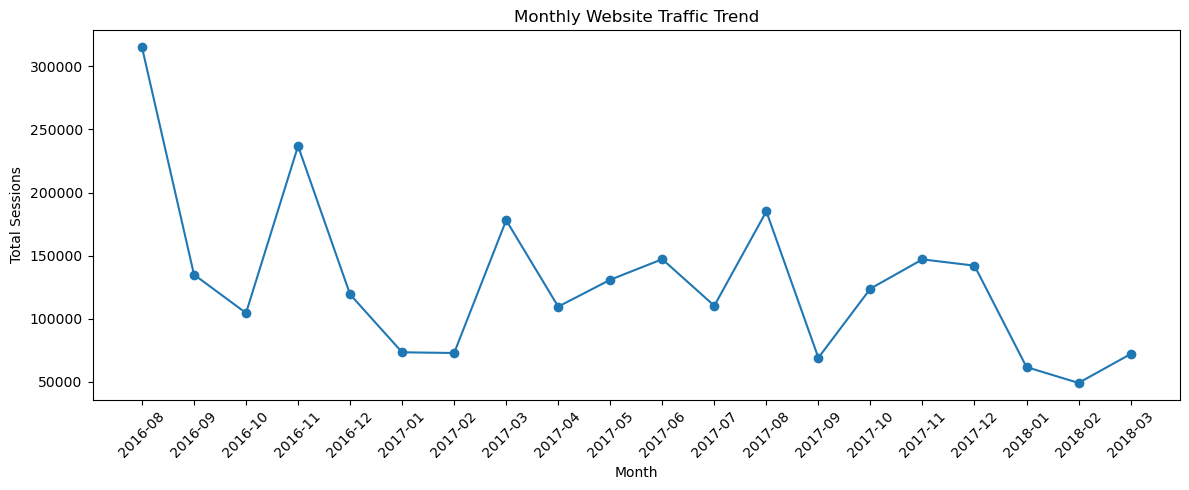

In [116]:
# ============================================================
# Visualization 1: Monthly Website Sessions Trend
# ============================================================
# 目的：
# 将每天的网站 session 汇总到“每月”，观察网站流量随时间的变化趋势。
# 相比每天的数据，月度趋势更容易看出整体增长、下降和季节性变化。

import matplotlib.pyplot as plt

# 按月份汇总 sessions
monthly_traffic = (
    traffic_clean
    .assign(
        month=traffic_clean["date_day"].dt.to_period("M").astype(str)
    )
    .groupby("month", as_index=False)
    .agg(
        monthly_sessions=("sessions", "sum")
    )
)

# 画月度网站流量趋势图
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_traffic["month"],
    monthly_traffic["monthly_sessions"],
    marker="o"
)

plt.title("Monthly Website Traffic Trend")
plt.xlabel("Month")
plt.ylabel("Total Sessions")

# 月份较多，因此旋转 x 轴标签，避免重叠
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

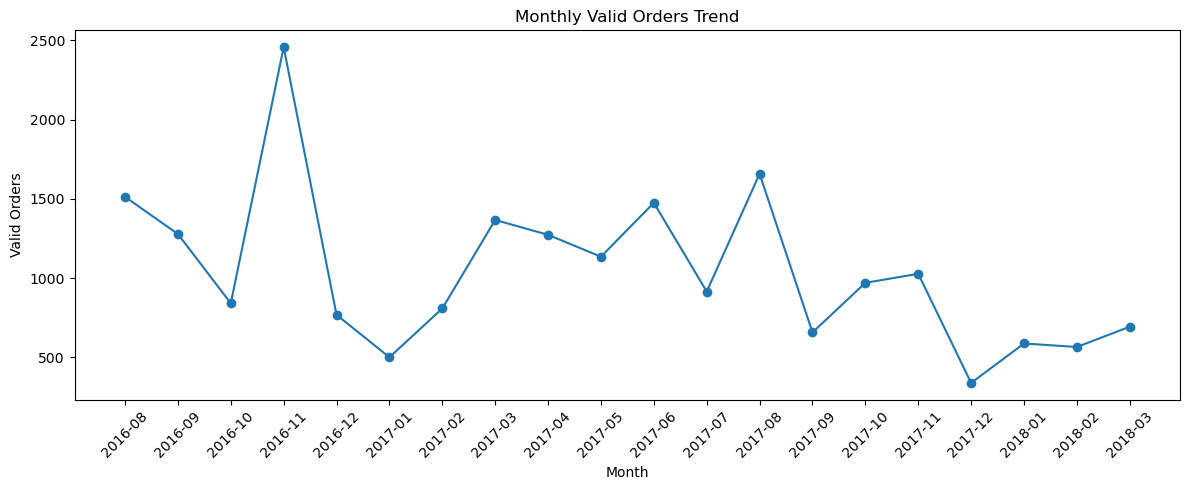

In [72]:
# ============================================================
# Visualization 2: Monthly Valid Orders Trend
# ============================================================
# 目的：
# 将每天的有效订单数量汇总到“每月”，
# 观察订单量随时间的整体变化趋势。
#
# 这张图可以与 Monthly Website Traffic Trend 对照，
# 判断网站流量增加或减少时，订单量是否也呈现类似变化。

# 按月份汇总有效订单数量
monthly_orders = (
    conversion_period
    .assign(
        month=conversion_period["date_day"].dt.to_period("M").astype(str)
    )
    .groupby("month", as_index=False)
    .agg(
        monthly_valid_orders=("valid_orders", "sum")
    )
)

# 绘制月度有效订单趋势
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_orders["month"],
    monthly_orders["monthly_valid_orders"],
    marker="o"
)

plt.title("Monthly Valid Orders Trend")
plt.xlabel("Month")
plt.ylabel("Valid Orders")

# 防止月份标签重叠
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

从月度趋势来看，网站流量与有效订单数量整体呈现相似的波动方向。部分流量高峰也对应较高的订单量，说明网站流量与订单之间存在一定的正向关系。但两者并不是完全同步，有些月份流量较高，但订单量并没有同比例上升，说明仅增加流量并不能保证订单增长，不同月份的转化效率可能存在差异。因此，除了关注流量规模之外，还需要进一步分析网站的转化率表现。

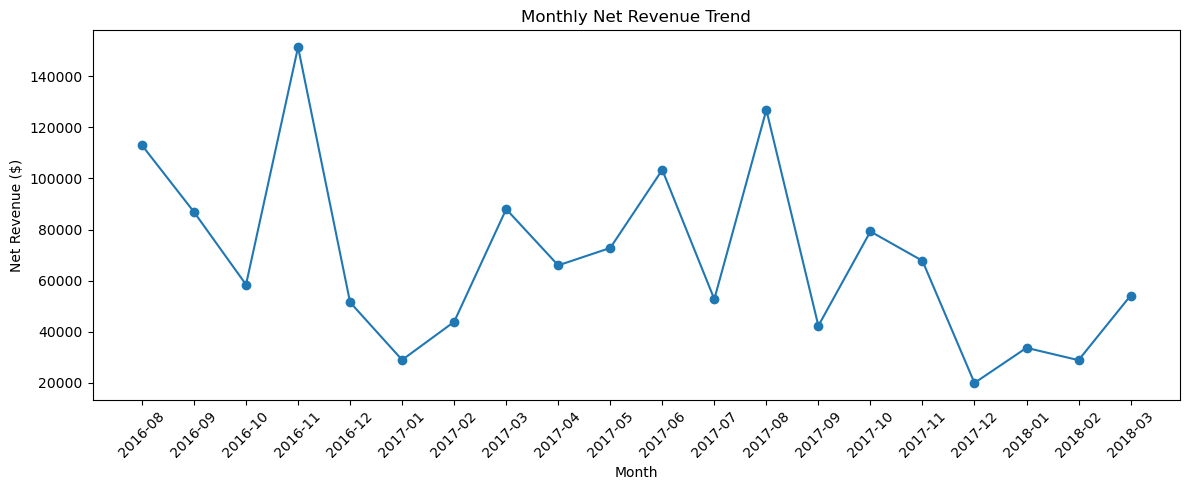

In [73]:
# ============================================================
# Visualization 3: Monthly Net Revenue Trend
# ============================================================
# 目的：
# 将有效订单的净收入按月份汇总，
# 观察店铺销售收入随时间的变化趋势。
#
# kpi_net_revenue 已考虑成功付款和退款，
# 因此比直接使用 total_price 更接近实际收入。

monthly_revenue = (
    orders_analysis[
        orders_analysis["is_valid_sales_order"]
    ]
    .groupby("order_month", as_index=False)
    .agg(
        monthly_net_revenue=("kpi_net_revenue", "sum")
    )
    .sort_values("order_month")
)

plt.figure(figsize=(12, 5))

plt.plot(
    monthly_revenue["order_month"].astype(str),
    monthly_revenue["monthly_net_revenue"],
    marker="o"
)

plt.title("Monthly Net Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Net Revenue ($)")

plt.xticks(rotation=45)

# 让纵轴金额显示得更容易阅读
plt.ticklabel_format(
    style="plain",
    axis="y"
)

plt.tight_layout()
plt.show()

In [74]:
# Session-to-Order Conversion Rate
# 使用 traffic 与 orders 都有数据的共同时间范围，避免时间区间不一致造成偏差。
total_sessions = conversion_period["sessions"].sum()
total_conversion_orders = conversion_period["valid_orders"].sum()

conversion_rate = total_conversion_orders / total_sessions * 100

print(f"Total Sessions: {total_sessions:,}")
print(f"Valid Orders in Traffic Period: {total_conversion_orders:,}")
print(f"Session-to-Order Conversion Rate: {conversion_rate:.2f}%")


Total Sessions: 2,583,027
Valid Orders in Traffic Period: 20,826
Session-to-Order Conversion Rate: 0.81%


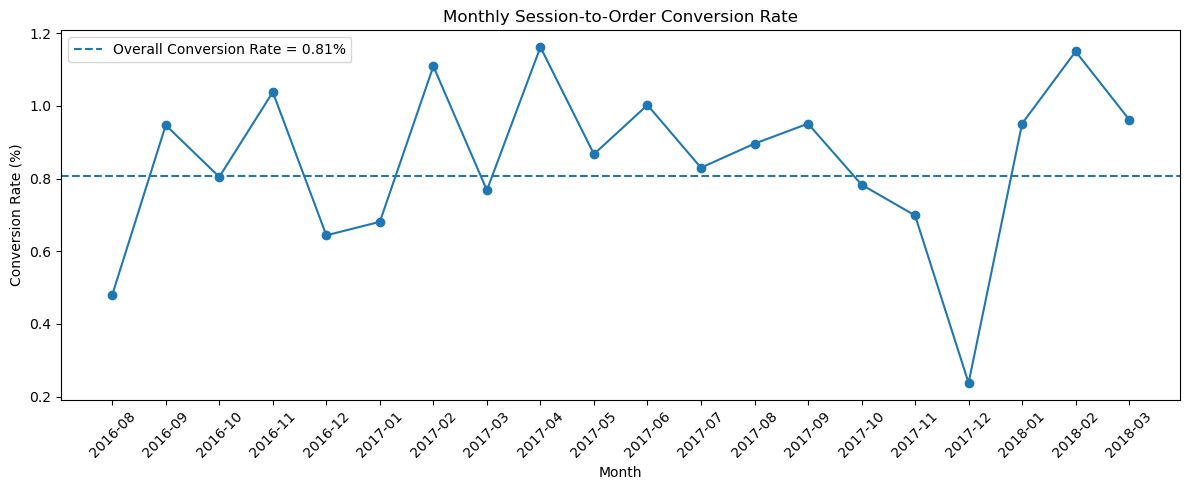

In [75]:
# ============================================================
# Visualization: Monthly Session-to-Order Conversion Rate
# ============================================================
# 目的：
# 按月份计算 Session → Valid Order 的转化率，
# 观察不同月份的网站转化效率是否存在明显变化。
#
# Monthly Conversion Rate
# = Monthly Valid Orders / Monthly Sessions × 100

monthly_conversion = (
    conversion_period
    .assign(
        month=conversion_period["date_day"].dt.to_period("M").astype(str)
    )
    .groupby("month", as_index=False)
    .agg(
        monthly_sessions=("sessions", "sum"),
        monthly_valid_orders=("valid_orders", "sum")
    )
)

# 计算每个月的转化率
monthly_conversion["conversion_rate"] = (
    monthly_conversion["monthly_valid_orders"]
    / monthly_conversion["monthly_sessions"]
    * 100
)

# 绘图
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_conversion["month"],
    monthly_conversion["conversion_rate"],
    marker="o"
)

plt.title("Monthly Session-to-Order Conversion Rate")
plt.xlabel("Month")
plt.ylabel("Conversion Rate (%)")

plt.xticks(rotation=45)

# 加一条整体平均转化率参考线
plt.axhline(
    conversion_rate,
    linestyle="--",
    label=f"Overall Conversion Rate = {conversion_rate:.2f}%"
)

plt.legend()
plt.tight_layout()
plt.show()

In [76]:
# Funnel 指标
total_product_views = conversion_period["product_detail_views"].sum()
total_add_to_carts = conversion_period["product_adds_to_carts"].sum()
total_checkouts = conversion_period["product_checkouts"].sum()

# 注意：product_detail_views 是页面浏览次数，不是独立 session 数，
# 因此 Session → Product View 不应严格称为 conversion rate。
product_views_per_session = total_product_views / total_sessions

product_to_cart_rate = total_add_to_carts / total_product_views * 100
cart_to_checkout_rate = total_checkouts / total_add_to_carts * 100
checkout_to_order_rate = total_conversion_orders / total_checkouts * 100

print(f"Product Detail Views per Session: {product_views_per_session:.2f}")
print(f"Product View → Add to Cart: {product_to_cart_rate:.2f}%")
print(f"Add to Cart → Checkout: {cart_to_checkout_rate:.2f}%")
print(f"Checkout → Order: {checkout_to_order_rate:.2f}%")
print(f"Session → Order Conversion: {conversion_rate:.2f}%")


Product Detail Views per Session: 1.11
Product View → Add to Cart: 10.08%
Add to Cart → Checkout: 29.21%
Checkout → Order: 24.66%
Session → Order Conversion: 0.81%


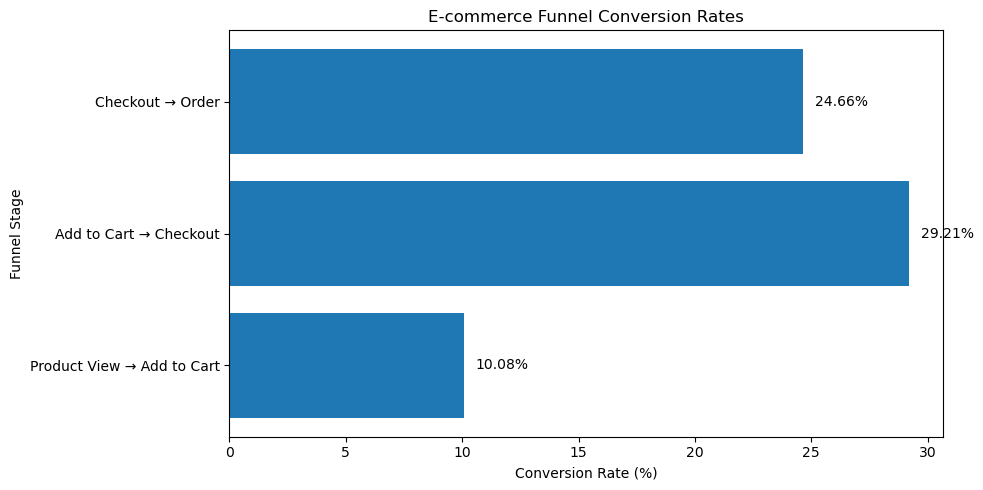

In [117]:
# ============================================================
# Visualization 4: Funnel Conversion Rates
# ============================================================

funnel_rates = pd.DataFrame({
    "Stage": [
        "Product View → Add to Cart",
        "Add to Cart → Checkout",
        "Checkout → Order"
    ],
    "Conversion Rate": [
        product_to_cart_rate,
        cart_to_checkout_rate,
        checkout_to_order_rate
    ]
})

plt.figure(figsize=(10, 5))

plt.barh(
    funnel_rates["Stage"],
    funnel_rates["Conversion Rate"]
)

plt.title("E-commerce Funnel Conversion Rates")
plt.xlabel("Conversion Rate (%)")
plt.ylabel("Funnel Stage")

# 在柱子后面显示百分比
for index, value in enumerate(funnel_rates["Conversion Rate"]):
    plt.text(
        value + 0.5,
        index,
        f"{value:.2f}%",
        va="center"
    )

# 给左边较长的标签留更多空间
plt.subplots_adjust(left=0.38)

plt.tight_layout()
plt.show()

Add to Cart → Checkout 是三个阶段里表现最好的，29.21%。
这说明一旦用户愿意把商品加入购物车，他们继续进入 checkout 的意愿相对更高。换句话说，问题更可能出现在“让用户产生购买兴趣”之前，而不是购物车页面本身。
Checkout → Order 只有 24.66%，仍然存在明显流失。
也就是说，进入 checkout 的用户中，大约只有四分之一最终形成有效订单。这里可能值得后续检查付款失败、运费、价格变化、结账流程等，但这些具体原因不能只靠这张图确定。
漏斗不是逐步越来越低的传统漏斗形状。
因为这里画的是“每一阶段到下一阶段的转化率”，不是每阶段剩余用户数量。所以 29.21% > 24.66% > 10.08% 是正常的，不代表数据错了。
前端兴趣转化是最明显的瓶颈。
10.08% 和后面两个 20%+ 的转化率差距很大，因此如果要选一个最优先优化的环节，Product View → Add to Cart 最值得关注。

In [78]:
# ============================================================
# Traffic 与 Orders 的相关性分析
# ============================================================
# Pearson correlation 用来衡量每天 sessions 和 valid_orders
# 是否存在正向或负向线性关系。
#
# 相关系数范围：
#  1   = 强正相关
#  0   = 基本无线性相关
# -1   = 强负相关

traffic_order_corr = conversion_period[
    "sessions"
].corr(
    conversion_period["valid_orders"]
)

print(
    f"Correlation between Sessions and Valid Orders: "
    f"{traffic_order_corr:.3f}"
)

Correlation between Sessions and Valid Orders: 0.770


session → Product View 超过 100% 并不代表错误。因为一个 session 里用户可能看多个 product detail pages，所以 product_detail_views 是“浏览次数”，不是“进入商品页的独立 session 数”。因此这个指标不能严格叫 conversion rate，更准确叫：Product Detail Views per Session

意思是平均每个 session 产生约 1.11 次商品详情页浏览

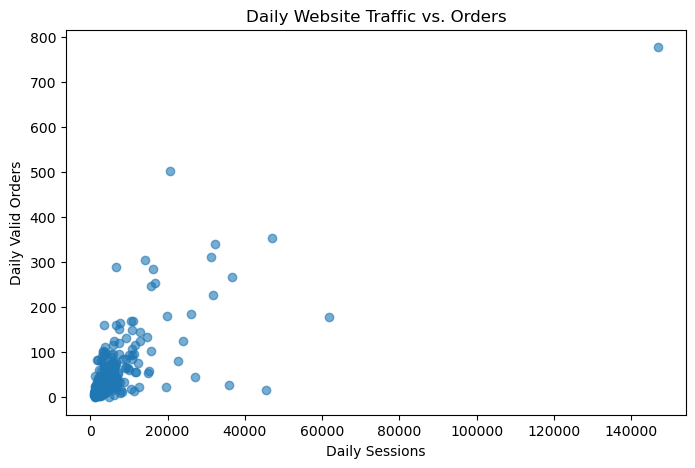

In [79]:
#加一个 scatter plot

plt.figure(figsize=(8, 5))

plt.scatter(
    conversion_period["sessions"],
    conversion_period["valid_orders"],
    alpha=0.6
)

plt.xlabel("Daily Sessions")
plt.ylabel("Daily Valid Orders")
plt.title("Daily Website Traffic vs. Orders")

plt.show()

从散点图来看，每日网站流量和有效订单数量整体呈现正向关系，即流量较高的日期通常也会产生更多订单。但数据点分布比较分散，而且存在少数极端高流量日期，因此流量并不是决定订单量的唯一因素。不同日期的转化效率可能存在明显差异。

## Traffic and Orders Relationship Visualizations

下面两张图用于检查网站流量与订单数量的时间关系，以及各网站行为指标与订单数量之间的相关性。


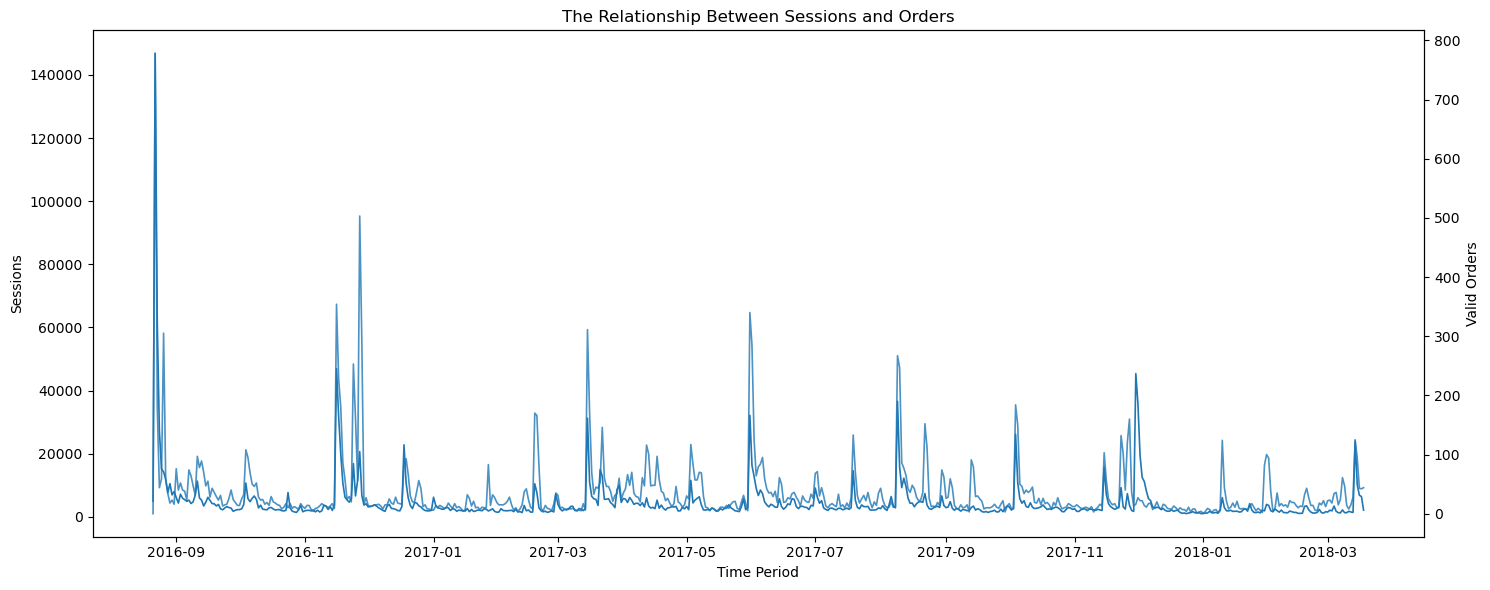

In [80]:
# ============================================================
# Visualization: Daily Sessions and Valid Orders Over Time
# 双 Y 轴：左边 Sessions，右边 Valid Orders
# ============================================================

fig, ax1 = plt.subplots(figsize=(15, 6))

# 左轴：Sessions
ax1.plot(
    conversion_period["date_day"],
    conversion_period["sessions"],
    linewidth=1.2,
    label="Sessions"
)
ax1.set_xlabel("Time Period")
ax1.set_ylabel("Sessions")

# 右轴：Valid Orders
ax2 = ax1.twinx()
ax2.plot(
    conversion_period["date_day"],
    conversion_period["valid_orders"],
    linewidth=1.2,
    alpha=0.8,
    label="Valid Orders"
)
ax2.set_ylabel("Valid Orders")

plt.title("The Relationship Between Sessions and Orders")
fig.tight_layout()
plt.show()


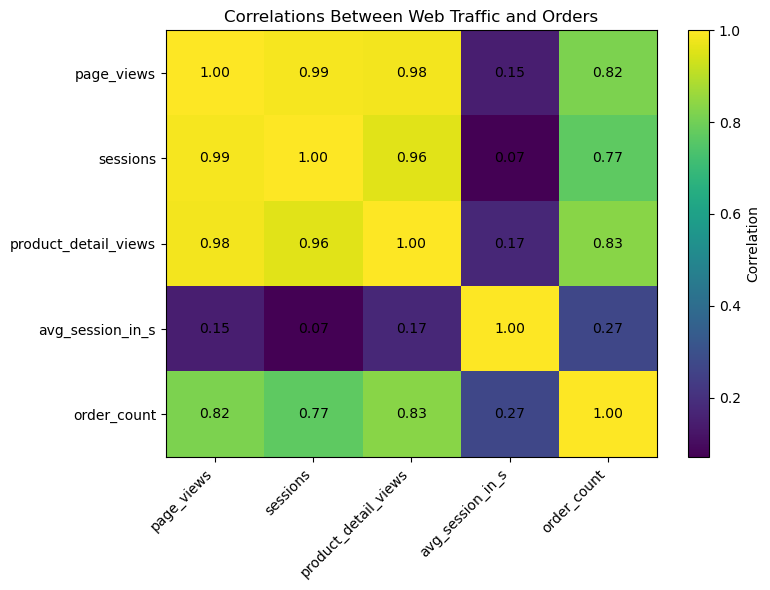

,page_views,sessions,product_detail_views,avg_session_in_s,order_count
page_views,1.000000,0.989084,0.984880,0.149932,0.818055
sessions,0.989084,1.000000,0.959449,0.070626,0.769538
product_detail_views,0.984880,0.959449,1.000000,0.173711,0.833915
avg_session_in_s,0.149932,0.070626,0.173711,1.000000,0.268720
order_count,0.818055,0.769538,0.833915,0.268720,1.000000


In [118]:
# ============================================================
# Visualization: Correlation Heatmap between Web Traffic and Orders
# 不使用 seaborn，直接用 matplotlib
# ============================================================

correlation_data = conversion_period[[
    "page_views",
    "sessions",
    "product_detail_views",
    "avg_session_in_s",
    "valid_orders"
]].copy()

correlation_data = correlation_data.rename(
    columns={"valid_orders": "order_count"}
)

corr_matrix = correlation_data.corr()

fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(corr_matrix.values, aspect="auto")

ax.set_xticks(range(len(corr_matrix.columns)))
ax.set_yticks(range(len(corr_matrix.index)))
ax.set_xticklabels(corr_matrix.columns, rotation=45, ha="right")
ax.set_yticklabels(corr_matrix.index)

# 在每个格子里显示相关系数
for i in range(len(corr_matrix.index)):
    for j in range(len(corr_matrix.columns)):
        ax.text(
            j, i,
            f"{corr_matrix.iloc[i, j]:.2f}",
            ha="center",
            va="center"
        )

fig.colorbar(im, ax=ax, label="Correlation")
plt.title("Correlations Between Web Traffic and Orders")
plt.tight_layout()
plt.show()

corr_matrix


In [82]:
# 将 Session-to-Order Conversion Rate 加入最终 KPI 展示表
conversion_row = pd.DataFrame({
    "KPI": ["Session-to-Order Conversion Rate"],
    "Value": [f"{conversion_rate:.2f}%"]
})

kpi_display = pd.concat(
    [kpi_display, conversion_row],
    ignore_index=True
)

kpi_display

,KPI,Value
0,Total Orders,"21,358"
1,Valid Sales Orders,"20,948"
2,Valid Order Rate,98.08%
3,Gross Successful Payments,"$1,579,872.23"
4,Successful Refund Amount,"$210,601.78"
5,Net Revenue,"$1,369,270.45"
6,Average Order Value,$65.37
7,Cancellation Rate,1.92%
8,Refund Order Rate,14.91%
9,Refund Amount Rate,13.33%


网站流量到订单的最终转化率不高。 Session-to-Order Conversion Rate 是 0.81%。直观上可以理解成每 100 个 session，大约只有 0.81 个订单

# Objective 2A: Customer Lifetime Value (Observed CLV)

This section builds one **customer-level value table** before segmentation.

- **Observed CLV** = total net revenue contributed by a customer during the available data period.
- It is an historical / observed value, **not** a prediction of future lifetime value.
- This table becomes the base for the RFM and K-Means customer segmentation that follows.


In [83]:
# ============================================================
# Step 1: Build customer-level Observed CLV
# ============================================================

# Only valid sales orders with a usable net-revenue value are included.
clv_orders = orders_analysis[
    orders_analysis["is_valid_sales_order"]
    & orders_analysis["kpi_net_revenue"].notna()
].copy()

print("Orders used for CLV:", len(clv_orders))
print("Customers used for CLV:", clv_orders["customer_id"].nunique())


Orders used for CLV: 20947
Customers used for CLV: 14758


In [84]:
# Aggregate order-level data to customer level:
# one row = one customer
customer_clv = (
    clv_orders
    .groupby("customer_id", as_index=False)
    .agg(
        total_orders=("order_id", "nunique"),
        lifetime_net_revenue=("kpi_net_revenue", "sum"),
        average_order_value=("kpi_net_revenue", "mean"),
        first_order_date=("order_created_at", "min"),
        last_order_date=("order_created_at", "max")
    )
)

# Observed CLV is the cumulative net revenue realized during the dataset period.
customer_clv["observed_clv"] = customer_clv["lifetime_net_revenue"]

# Customer purchasing lifespan within the observed period.
customer_clv["purchase_lifespan_days"] = (
    customer_clv["last_order_date"] - customer_clv["first_order_date"]
).dt.days

customer_clv.head()


,customer_id,total_orders,lifetime_net_revenue,average_order_value,first_order_date,last_order_date,observed_clv,purchase_lifespan_days
0,8683754719,3,189.88,63.293333,2016-09-15,2017-03-30,189.88,196
1,8686224991,9,7.00,0.777778,2016-08-22,2017-01-31,7.00,162
2,8686913503,3,140.28,46.760000,2016-11-17,2017-06-02,140.28,197
3,8686915935,1,131.10,131.100000,2016-08-22,2016-08-22,131.10,0
4,8686924319,1,91.12,91.120000,2016-08-22,2016-08-22,91.12,0


In [85]:
# ============================================================
# Step 2: Add Recency and Repeat-Purchase Information
# ============================================================

# Analysis date = one day after the latest order in the dataset.
analysis_date = orders_analysis["order_created_at"].max() + pd.Timedelta(days=1)

customer_clv["recency_days"] = (
    analysis_date - customer_clv["last_order_date"]
).dt.days

customer_clv["is_repeat_customer"] = customer_clv["total_orders"] >= 2

print("Analysis date:", analysis_date)

customer_clv[
    [
        "customer_id",
        "total_orders",
        "observed_clv",
        "average_order_value",
        "recency_days",
        "purchase_lifespan_days",
        "is_repeat_customer"
    ]
].head(20)


Analysis date: 2018-03-23 00:00:00


,customer_id,total_orders,observed_clv,average_order_value,recency_days,purchase_lifespan_days,is_repeat_customer
0,8683754719,3,189.88,63.293333,358,196,True
1,8686224991,9,7.00,0.777778,416,162,True
2,8686913503,3,140.28,46.760000,294,197,True
3,8686915935,1,131.10,131.100000,578,0,False
4,8686924319,1,91.12,91.120000,578,0,False
5,8687041311,1,75.00,75.000000,578,0,False
6,8687102111,1,78.84,78.840000,295,0,False
7,8687175327,2,115.60,57.800000,343,235,True
8,8687301023,3,112.41,37.470000,170,408,True
9,8687317279,1,94.40,94.400000,578,0,False


In [86]:
# ============================================================
# Step 3: CLV Summary Statistics
# ============================================================

average_observed_clv = customer_clv["observed_clv"].mean()
median_observed_clv = customer_clv["observed_clv"].median()

print(f"Average Observed CLV: ${average_observed_clv:,.2f}")
print(f"Median Observed CLV: ${median_observed_clv:,.2f}")

customer_clv["observed_clv"].describe()


Average Observed CLV: $92.78
Median Observed CLV: $62.80


count    14758.000000
mean        92.781573
std        125.172320
min          0.000000
25%         37.660000
50%         62.800000
75%        105.300000
max       4945.000000
Name: observed_clv, dtype: float64

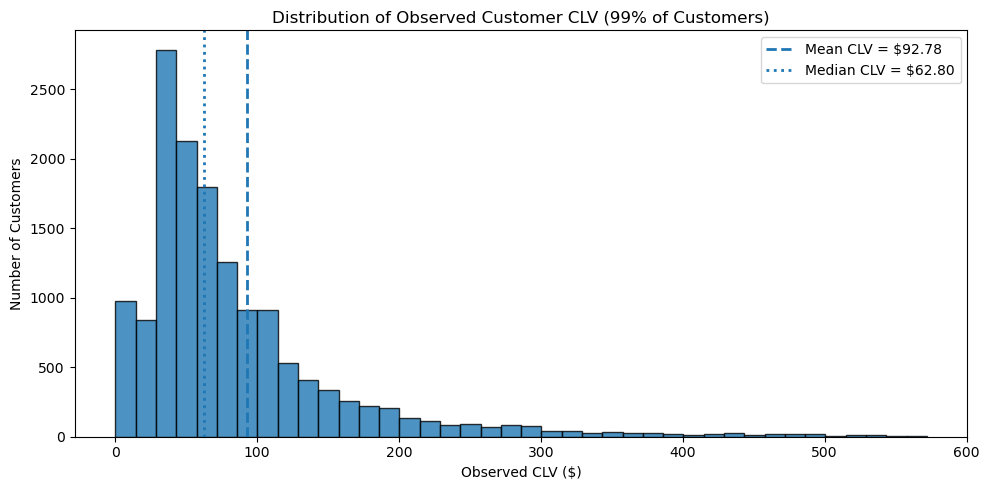

In [87]:
# ============================================================
# Visualization: CLV Distribution (Zoomed to 99th Percentile)
# ============================================================

# We only limit the DISPLAY range to the 99th percentile.
# High-value customers are NOT removed from the dataset.
clv_99 = customer_clv["observed_clv"].quantile(0.99)

plt.figure(figsize=(10, 5))

plt.hist(
    customer_clv["observed_clv"],
    bins=40,
    range=(0, clv_99),
    edgecolor="black",
    alpha=0.8
)

plt.axvline(
    average_observed_clv,
    linestyle="--",
    linewidth=2,
    label=f"Mean CLV = ${average_observed_clv:,.2f}"
)

plt.axvline(
    median_observed_clv,
    linestyle=":",
    linewidth=2,
    label=f"Median CLV = ${median_observed_clv:,.2f}"
)

plt.title("Distribution of Observed Customer CLV (99% of Customers)")
plt.xlabel("Observed CLV ($)")
plt.ylabel("Number of Customers")
plt.legend()
plt.tight_layout()
plt.show()


### CLV interpretation

Observed CLV is strongly right-skewed: most customers contribute relatively modest value, while a small number of customers contribute much more. In the existing notebook output, mean Observed CLV is about **$92.78** and median Observed CLV is about **$62.80**. The median is therefore more representative of a typical customer, while the upper tail identifies customers with unusually high realized value.


In [88]:
# ============================================================
# Step 4: Add Customer Information and Save CLV Table
# ============================================================

customer_clv = customer_clv.merge(
    customers_clean[["id", "full_name", "created_at"]],
    left_on="customer_id",
    right_on="id",
    how="left",
    validate="one_to_one"
)

customer_clv = (
    customer_clv
    .rename(columns={"created_at": "customer_created_at"})
    .drop(columns=["id"])
)

customer_clv.to_csv(
    f"{PROCESSED_DATA_DIR}/customer_clv.csv",
    index=False
)

print("Customer CLV dataset saved successfully!")


Customer CLV dataset saved successfully!


In [89]:
# Add CLV metrics to the KPI summary table
clv_rows = pd.DataFrame({
    "KPI": [
        "Average Observed CLV",
        "Median Observed CLV"
    ],
    "Value": [
        f"${average_observed_clv:,.2f}",
        f"${median_observed_clv:,.2f}"
    ]
})

kpi_display = pd.concat(
    [kpi_display, clv_rows],
    ignore_index=True
)

kpi_display


,KPI,Value
0,Total Orders,"21,358"
1,Valid Sales Orders,"20,948"
2,Valid Order Rate,98.08%
3,Gross Successful Payments,"$1,579,872.23"
4,Successful Refund Amount,"$210,601.78"
5,Net Revenue,"$1,369,270.45"
6,Average Order Value,$65.37
7,Cancellation Rate,1.92%
8,Refund Order Rate,14.91%
9,Refund Amount Rate,13.33%


# Objective 2B: RFM Customer Features

RFM is used here to describe each customer's purchasing behavior and to provide the three features used by K-Means:

- **R — Recency:** days since the customer's most recent purchase; lower is better.
- **F — Frequency:** number of valid orders; higher means more repeat purchasing.
- **M — Monetary:** Observed CLV / cumulative net revenue; higher means greater realized customer value.

**Important:** RFM scores below are descriptive only. They are **not** used to assign the final customer segment. Final segment labels come from the K-Means clustering results.


In [90]:
# ============================================================
# Step 1: Create RFM Dataset
# ============================================================

rfm = customer_clv[
    [
        "customer_id",
        "recency_days",
        "total_orders",
        "observed_clv",
        "average_order_value",
        "purchase_lifespan_days",
        "is_repeat_customer"
    ]
].copy()

rfm = rfm.rename(
    columns={
        "recency_days": "recency",
        "total_orders": "frequency",
        "observed_clv": "monetary"
    }
)

rfm[["recency", "frequency", "monetary"]].describe()


,recency,frequency,monetary
count,14758.000000,14758.000000,14758.000000
mean,316.143312,1.419366,92.781573
std,169.124719,3.117599,125.172320
min,1.000000,1.000000,0.000000
25%,190.000000,1.000000,37.660000
50%,320.000000,1.000000,62.800000
75%,481.000000,1.000000,105.300000
max,578.000000,354.000000,4945.000000


## Optional descriptive RFM scores

These scores are retained only for the RFM heatmap and descriptive analysis. They do **not** define Champions, Loyal Customers, At Risk, or any other manual segment.


In [91]:
# Recency: lower is better.
# rank(method="first") avoids duplicate qcut boundaries.
rfm["R_score"] = pd.qcut(
    rfm["recency"].rank(method="first"),
    q=4,
    labels=[4, 3, 2, 1]
).astype(int)

# Frequency has many one-order customers, so use interpretable frequency bins.
def frequency_score(x):
    if x == 1:
        return 1
    elif x == 2:
        return 2
    elif x <= 4:
        return 3
    else:
        return 4

rfm["F_score"] = rfm["frequency"].apply(frequency_score)

# Monetary: higher is better.
rfm["M_score"] = pd.qcut(
    rfm["monetary"].rank(method="first"),
    q=4,
    labels=[1, 2, 3, 4]
).astype(int)

rfm["RFM_score"] = rfm["R_score"] + rfm["F_score"] + rfm["M_score"]

rfm[
    [
        "customer_id", "recency", "frequency", "monetary",
        "R_score", "F_score", "M_score", "RFM_score"
    ]
].head(20)


,customer_id,recency,frequency,monetary,R_score,F_score,M_score,RFM_score
0,8683754719,358,3,189.88,2,3,4,9
1,8686224991,416,9,7.00,2,4,1,7
2,8686913503,294,3,140.28,3,3,4,10
3,8686915935,578,1,131.10,1,1,4,6
4,8686924319,578,1,91.12,1,1,3,5
5,8687041311,578,1,75.00,1,1,3,5
6,8687102111,295,1,78.84,3,1,3,7
7,8687175327,343,2,115.60,2,2,4,8
8,8687301023,170,3,112.41,4,3,4,11
9,8687317279,578,1,94.40,1,1,3,5


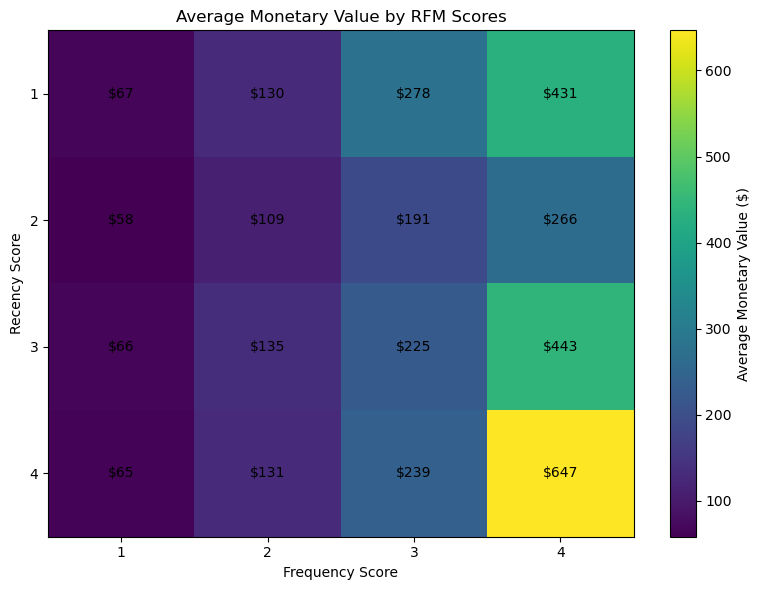

In [92]:
# ============================================================
# Visualization: RFM Heatmap
# ============================================================

rfm_heatmap = rfm.pivot_table(
    index="R_score",
    columns="F_score",
    values="monetary",
    aggfunc="mean"
)

plt.figure(figsize=(8, 6))
plt.imshow(rfm_heatmap, aspect="auto")
plt.colorbar(label="Average Monetary Value ($)")

plt.xticks(range(len(rfm_heatmap.columns)), rfm_heatmap.columns)
plt.yticks(range(len(rfm_heatmap.index)), rfm_heatmap.index)

plt.xlabel("Frequency Score")
plt.ylabel("Recency Score")
plt.title("Average Monetary Value by RFM Scores")

for i in range(len(rfm_heatmap.index)):
    for j in range(len(rfm_heatmap.columns)):
        value = rfm_heatmap.iloc[i, j]
        if pd.notna(value):
            plt.text(j, i, f"${value:.0f}", ha="center", va="center")

plt.tight_layout()
plt.show()


# Objective 2C: Machine Learning Customer Segmentation with K-Means

The final customer segmentation is now produced **only by K-Means**. There is no separate rule-based customer classification.

Workflow:

1. Use Recency, Frequency, and Monetary as clustering features.
2. Apply `log1p()` to reduce skewness.
3. Standardize the three features.
4. Compare K = 2–8 using Inertia and Silhouette Score.
5. Train the final K-Means model.
6. Profile each cluster using its original RFM values.
7. Convert the four clusters into interpretable business labels.
8. Merge the final cluster and segment back into the customer-level CLV table.


In [93]:
# ============================================================
# Step 1: Prepare RFM Features for K-Means
# ============================================================

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

rfm_ml = rfm[
    ["customer_id", "recency", "frequency", "monetary"]
].copy()

rfm_log = np.log1p(
    rfm_ml[["recency", "frequency", "monetary"]]
)

scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_log)

print("Customers used for clustering:", len(rfm_ml))
print("Scaled RFM shape:", rfm_scaled.shape)


Customers used for clustering: 14758
Scaled RFM shape: (14758, 3)


In [94]:
# ============================================================
# Step 2: Choose K with Elbow Method + Silhouette Score
# ============================================================

k_values = range(2, 9)
inertias = []
silhouette_scores = []

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(rfm_scaled)
    inertias.append(model.inertia_)
    silhouette_scores.append(
        silhouette_score(rfm_scaled, labels)
    )

k_evaluation = pd.DataFrame({
    "k": list(k_values),
    "inertia": inertias,
    "silhouette_score": silhouette_scores
})

best_k = int(
    k_evaluation.loc[
        k_evaluation["silhouette_score"].idxmax(),
        "k"
    ]
)

best_silhouette = float(k_evaluation["silhouette_score"].max())

print("Recommended K based on highest Silhouette Score:", best_k)
print(f"Best Silhouette Score: {best_silhouette:.3f}")

k_evaluation


Recommended K based on highest Silhouette Score: 4
Best Silhouette Score: 0.528


,k,inertia,silhouette_score
0,2,30112.445332,0.484952
1,3,22204.067110,0.503290
2,4,16182.430314,0.528258
3,5,12674.033923,0.509052
4,6,11007.078271,0.377776
5,7,9650.077813,0.362896
6,8,8765.903202,0.374275


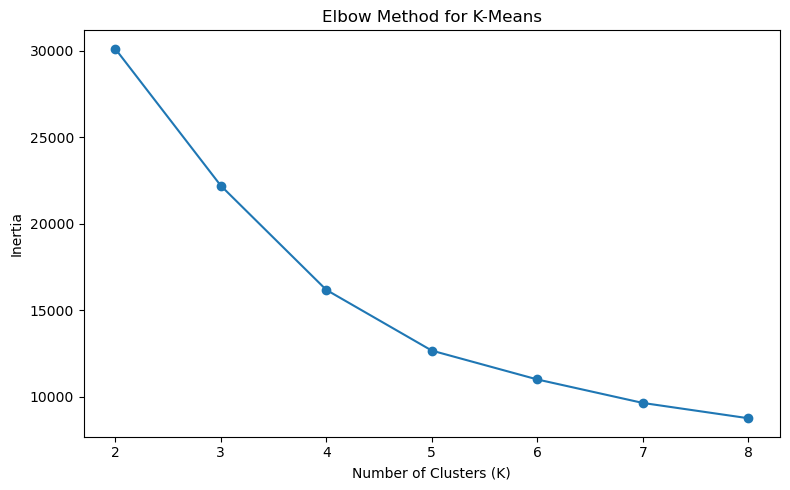

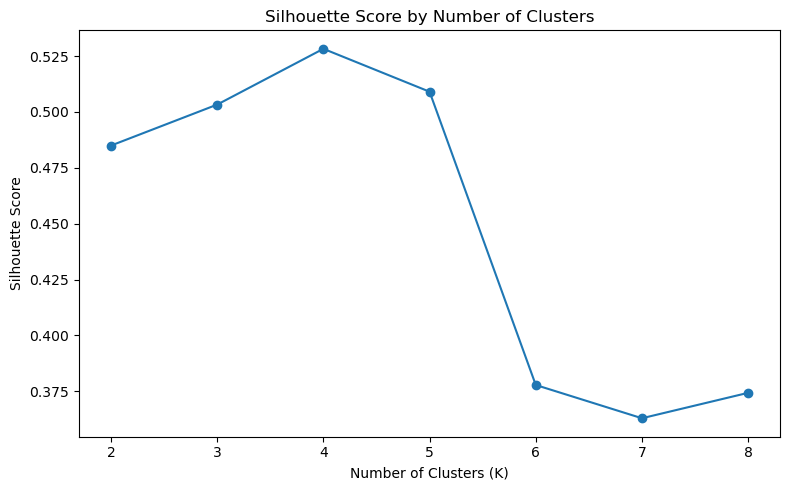

In [95]:
# Visualization: Elbow Method
plt.figure(figsize=(8, 5))
plt.plot(
    k_evaluation["k"],
    k_evaluation["inertia"],
    marker="o"
)
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for K-Means")
plt.xticks(k_evaluation["k"])
plt.tight_layout()
plt.show()

# Visualization: Silhouette Score
plt.figure(figsize=(8, 5))
plt.plot(
    k_evaluation["k"],
    k_evaluation["silhouette_score"],
    marker="o"
)
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score by Number of Clusters")
plt.xticks(k_evaluation["k"])
plt.tight_layout()
plt.show()


### Final K used in this dataset

The existing notebook output shows that **K = 4** has the highest Silhouette Score (about **0.528**), so four clusters are both statistically supported and easy to translate into four business-facing customer groups.

The code below keeps `best_k` from the evaluation step and verifies that four clusters were selected before applying the four business labels.


In [96]:
# ============================================================
# Step 3: Train Final K-Means Model
# ============================================================

kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

rfm_ml["cluster"] = kmeans.fit_predict(rfm_scaled)

print(
    rfm_ml["cluster"]
    .value_counts()
    .sort_index()
)


cluster
0    2583
1    1265
2    9970
3     940
Name: count, dtype: int64


In [97]:
# ============================================================
# Step 4: Profile Clusters Using Original RFM Values
# ============================================================

cluster_profile = (
    rfm_ml
    .groupby("cluster", as_index=False)
    .agg(
        customer_count=("customer_id", "nunique"),
        avg_recency=("recency", "mean"),
        median_recency=("recency", "median"),
        avg_frequency=("frequency", "mean"),
        median_frequency=("frequency", "median"),
        avg_monetary=("monetary", "mean"),
        median_monetary=("monetary", "median")
    )
)

cluster_profile["customer_percentage"] = (
    cluster_profile["customer_count"]
    / cluster_profile["customer_count"].sum()
    * 100
)

cluster_profile.round(2)


,cluster,customer_count,avg_recency,median_recency,avg_frequency,median_frequency,avg_monetary,median_monetary,customer_percentage
0,0,2583,254.39,233.0,3.14,2.0,224.21,157.00,17.50
1,1,1265,31.30,26.0,1.28,1.0,81.74,65.00,8.57
2,2,9970,369.70,365.0,1.02,1.0,68.54,55.49,67.56
3,3,940,301.08,295.0,1.09,1.0,3.63,7.00,6.37


In [98]:
# ============================================================
# Step 5: Assign Business Labels from Cluster Profiles
# ============================================================
# IMPORTANT:
# K-Means cluster numbers (0,1,2,3) have no inherent business meaning.
# Therefore labels are derived from the cluster PROFILE instead of
# permanently assuming that cluster 0/1/2/3 always means the same thing.

if best_k != 4:
    raise ValueError(
        f"The business-label logic below expects 4 clusters, but best_k={best_k}. "
        "Review k_evaluation before assigning the four business labels."
    )

profile_for_labeling = cluster_profile.set_index("cluster").copy()

# 1) Highest purchase frequency = strongest repeat / loyal behavior.
high_value_loyal_cluster = (
    profile_for_labeling["avg_frequency"].idxmax()
)

remaining_clusters = [
    c for c in profile_for_labeling.index
    if c != high_value_loyal_cluster
]

# 2) Among the remaining groups, lowest recency = most recently active.
recent_potential_cluster = (
    profile_for_labeling.loc[remaining_clusters, "avg_recency"].idxmin()
)

remaining_clusters = [
    c for c in remaining_clusters
    if c != recent_potential_cluster
]

# 3) Among the final two groups, lowest monetary value = low-value / at-risk.
low_value_at_risk_cluster = (
    profile_for_labeling.loc[remaining_clusters, "avg_monetary"].idxmin()
)

# 4) The remaining cluster is mainly one-time / low-engagement.
one_time_cluster = [
    c for c in remaining_clusters
    if c != low_value_at_risk_cluster
][0]

cluster_label_map = {
    high_value_loyal_cluster: "High-Value Loyal",
    recent_potential_cluster: "Recent / Potential",
    one_time_cluster: "One-time / Low Engagement",
    low_value_at_risk_cluster: "Low-Value / At Risk"
}

rfm_ml["customer_segment"] = rfm_ml["cluster"].map(cluster_label_map)

print("Cluster label mapping:")
for cluster_id, label in cluster_label_map.items():
    print(f"Cluster {cluster_id}: {label}")


Cluster label mapping:
Cluster 0: High-Value Loyal
Cluster 1: Recent / Potential
Cluster 2: One-time / Low Engagement
Cluster 3: Low-Value / At Risk


In [99]:
# Add business labels to the cluster profile
cluster_profile["customer_segment"] = (
    cluster_profile["cluster"].map(cluster_label_map)
)

cluster_profile = cluster_profile[
    [
        "cluster",
        "customer_segment",
        "customer_count",
        "customer_percentage",
        "avg_recency",
        "median_recency",
        "avg_frequency",
        "median_frequency",
        "avg_monetary",
        "median_monetary"
    ]
].sort_values("customer_percentage", ascending=False)

cluster_profile.round(2)


,cluster,customer_segment,customer_count,customer_percentage,avg_recency,median_recency,avg_frequency,median_frequency,avg_monetary,median_monetary
2,2,One-time / Low Engagement,9970,67.56,369.70,365.0,1.02,1.0,68.54,55.49
0,0,High-Value Loyal,2583,17.50,254.39,233.0,3.14,2.0,224.21,157.00
1,1,Recent / Potential,1265,8.57,31.30,26.0,1.28,1.0,81.74,65.00
3,3,Low-Value / At Risk,940,6.37,301.08,295.0,1.09,1.0,3.63,7.00


In [100]:
# ============================================================
# Step 6: Final Segment Distribution
# ============================================================

segment_counts = (
    rfm_ml["customer_segment"]
    .value_counts()
    .rename_axis("customer_segment")
    .reset_index(name="customer_count")
)

segment_counts["customer_percentage"] = (
    segment_counts["customer_count"]
    / segment_counts["customer_count"].sum()
    * 100
)

segment_counts["customer_percentage"] = (
    segment_counts["customer_percentage"].round(2)
)

segment_counts


,customer_segment,customer_count,customer_percentage
0,One-time / Low Engagement,9970,67.56
1,High-Value Loyal,2583,17.50
2,Recent / Potential,1265,8.57
3,Low-Value / At Risk,940,6.37


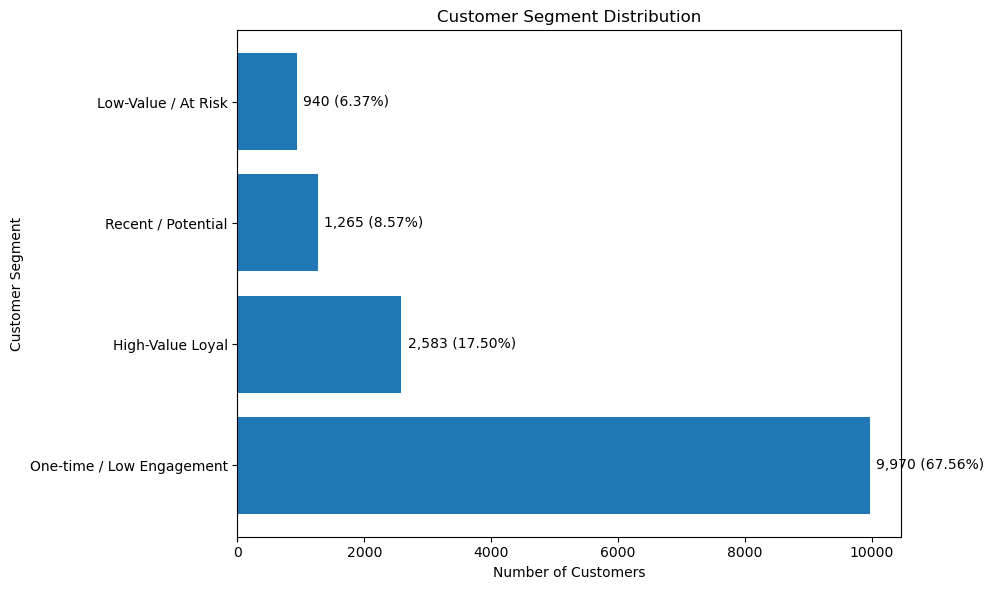

In [101]:
# Visualization: Customer Segment Distribution
plt.figure(figsize=(10, 6))

bars = plt.barh(
    segment_counts["customer_segment"],
    segment_counts["customer_count"]
)

plt.xlabel("Number of Customers")
plt.ylabel("Customer Segment")
plt.title("Customer Segment Distribution")

for bar, count, pct in zip(
    bars,
    segment_counts["customer_count"],
    segment_counts["customer_percentage"]
):
    plt.text(
        bar.get_width() + max(segment_counts["customer_count"]) * 0.01,
        bar.get_y() + bar.get_height() / 2,
        f"{count:,} ({pct:.2f}%)",
        va="center"
    )

plt.tight_layout()
plt.show()


# Objective 2D: Connect K-Means Segments Back to CLV

This is the piece that was missing after the earlier manual segmentation was deleted.

The final customer table now combines:

- customer information,
- Observed CLV,
- order frequency / recency,
- K-Means cluster,
- final K-Means business segment.

This makes CLV and clustering part of one continuous customer-analysis workflow.


In [102]:
# ============================================================
# Step 1: Merge Final K-Means Results Back to Customer CLV
# ============================================================

customer_analysis = customer_clv.merge(
    rfm_ml[
        [
            "customer_id",
            "recency",
            "frequency",
            "monetary",
            "cluster",
            "customer_segment"
        ]
    ],
    on="customer_id",
    how="left",
    validate="one_to_one"
)

customer_analysis.head()


,customer_id,total_orders,lifetime_net_revenue,average_order_value,first_order_date,last_order_date,observed_clv,purchase_lifespan_days,recency_days,is_repeat_customer,full_name,customer_created_at,recency,frequency,monetary,cluster,customer_segment
0,8683754719,3,189.88,63.293333,2016-09-15,2017-03-30,189.88,196,358,True,Donna Pierce,2016-08-21,358,3,189.88,0,High-Value Loyal
1,8686224991,9,7.00,0.777778,2016-08-22,2017-01-31,7.00,162,416,True,Ashley Montgomery,2016-08-22,416,9,7.00,0,High-Value Loyal
2,8686913503,3,140.28,46.760000,2016-11-17,2017-06-02,140.28,197,294,True,Timothy Johnson,2016-08-22,294,3,140.28,0,High-Value Loyal
3,8686915935,1,131.10,131.100000,2016-08-22,2016-08-22,131.10,0,578,False,Michael Ellis,2016-08-22,578,1,131.10,2,One-time / Low Engagement
4,8686924319,1,91.12,91.120000,2016-08-22,2016-08-22,91.12,0,578,False,Brad Miller,2016-08-22,578,1,91.12,2,One-time / Low Engagement


In [103]:
# ============================================================
# Step 2: CLV Summary by Final K-Means Segment
# ============================================================

segment_clv_summary = (
    customer_analysis
    .groupby("customer_segment", as_index=False)
    .agg(
        customer_count=("customer_id", "nunique"),
        mean_observed_clv=("observed_clv", "mean"),
        median_observed_clv=("observed_clv", "median"),
        mean_orders=("total_orders", "mean"),
        mean_recency_days=("recency_days", "mean")
    )
    .sort_values("mean_observed_clv", ascending=False)
)

segment_clv_summary.round(2)


,customer_segment,customer_count,mean_observed_clv,median_observed_clv,mean_orders,mean_recency_days
0,High-Value Loyal,2583,224.21,157.00,3.14,254.39
3,Recent / Potential,1265,81.74,65.00,1.28,31.30
2,One-time / Low Engagement,9970,68.54,55.49,1.02,369.70
1,Low-Value / At Risk,940,3.63,7.00,1.09,301.08


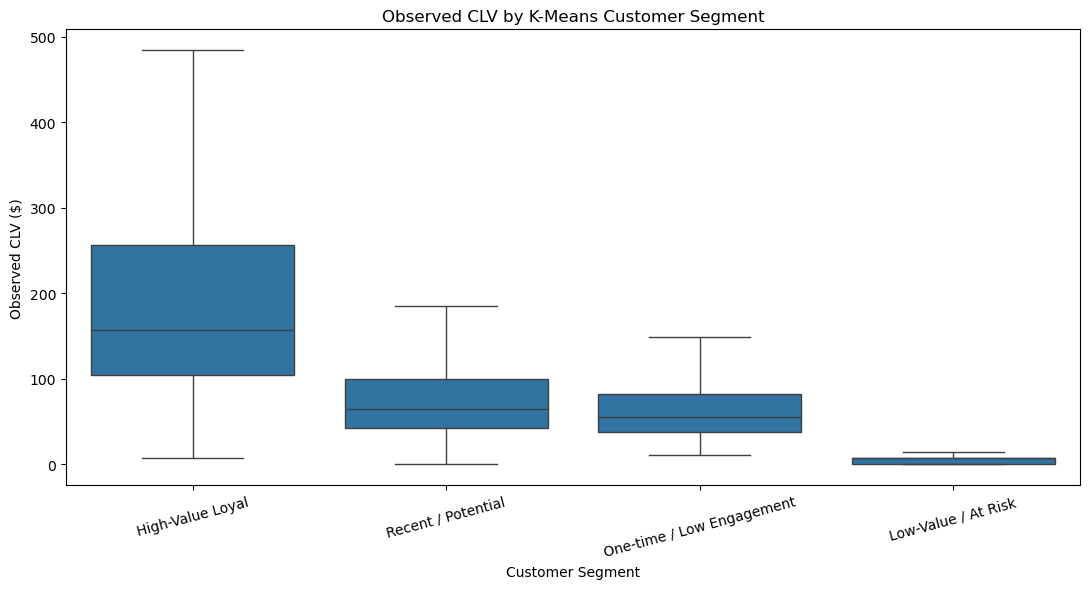

In [104]:
# ============================================================
# Visualization: Observed CLV by Final K-Means Segment
# ============================================================

import seaborn as sns

segment_order = (
    segment_clv_summary["customer_segment"].tolist()
)

plt.figure(figsize=(11, 6))

sns.boxplot(
    data=customer_analysis,
    x="customer_segment",
    y="observed_clv",
    order=segment_order,
    showfliers=False
)

plt.title("Observed CLV by K-Means Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Observed CLV ($)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


In [105]:
# ============================================================
# Step 3: Top 10 Customers by Observed CLV
# ============================================================

top_10_customers = (
    customer_analysis
    .sort_values("observed_clv", ascending=False)
    .head(10)
)

top_10_customers[
    [
        "customer_id",
        "full_name",
        "total_orders",
        "observed_clv",
        "average_order_value",
        "recency_days",
        "customer_segment"
    ]
]


,customer_id,full_name,total_orders,observed_clv,average_order_value,recency_days,customer_segment
642,8689371999,Rose Owen,25,4945.00,197.800000,128,High-Value Loyal
3790,8849705567,Katelyn Powell,17,2575.89,151.522941,120,High-Value Loyal
7489,413798176253,Kristen Hanson,27,2010.73,74.471481,9,High-Value Loyal
2191,8705718751,Becky Roberts,16,1990.02,124.376250,51,High-Value Loyal
68,8688010527,Ryan Gaines,16,1973.54,123.346250,9,High-Value Loyal
482,8689195551,Robert Whitehead,19,1849.48,97.341053,9,High-Value Loyal
12240,659535894013,Oscar Thomas,7,1846.40,263.771429,1,High-Value Loyal
347,8689047327,Charles Harvey,15,1700.60,113.373333,170,High-Value Loyal
1739,8693553375,Lacey Kline,12,1697.02,141.418333,70,High-Value Loyal
4602,228672476669,Jacqueline Payne,10,1573.61,157.361000,88,High-Value Loyal


Explained variance by 2 PCs: 82.76%


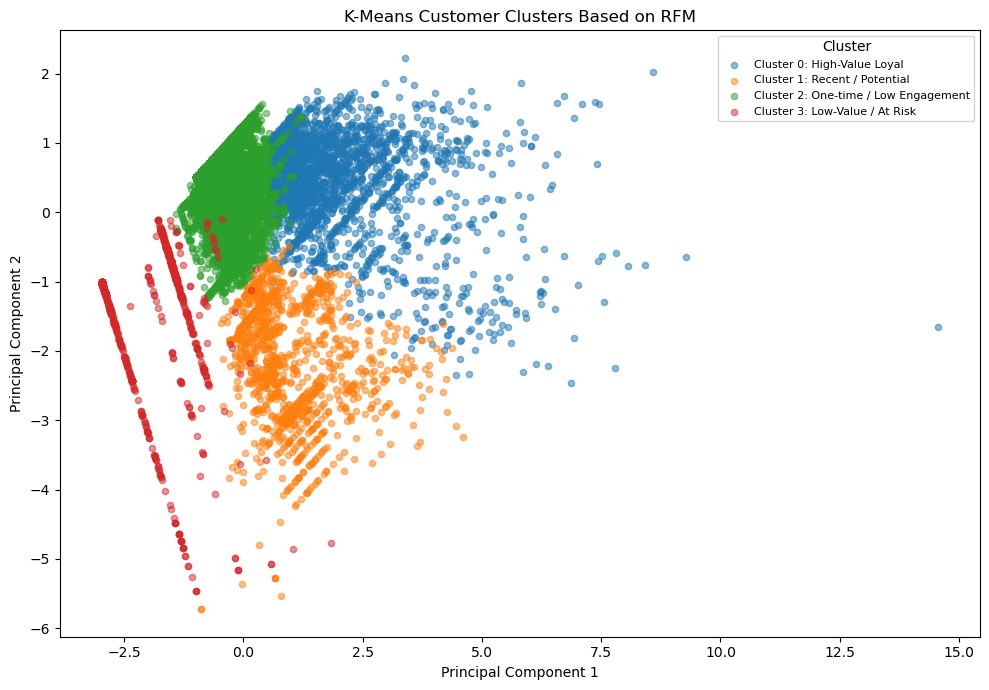

In [106]:
# ============================================================
# Step 4: PCA Visualization of K-Means Clusters
# ============================================================

pca = PCA(n_components=2)
rfm_pca = pca.fit_transform(rfm_scaled)

rfm_ml["PC1"] = rfm_pca[:, 0]
rfm_ml["PC2"] = rfm_pca[:, 1]

print(
    "Explained variance by 2 PCs:",
    f"{pca.explained_variance_ratio_.sum():.2%}"
)

plt.figure(figsize=(10, 7))

for cluster_id in sorted(rfm_ml["cluster"].unique()):
    cluster_data = rfm_ml[rfm_ml["cluster"] == cluster_id]

    plt.scatter(
        cluster_data["PC1"],
        cluster_data["PC2"],
        s=20,
        alpha=0.5,
        label=f"Cluster {cluster_id}: {cluster_label_map[cluster_id]}"
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Customer Clusters Based on RFM")
plt.legend(title="Cluster", fontsize=8)
plt.tight_layout()
plt.show()


In [107]:
# ============================================================
# Step 5: Save Final Customer Analysis Outputs
# ============================================================

customer_analysis.to_csv(
    f"{PROCESSED_DATA_DIR}/customer_analysis.csv",
    index=False,
    encoding="utf-8-sig"
)

rfm_ml.to_csv(
    f"{PROCESSED_DATA_DIR}/customer_rfm_kmeans_clusters.csv",
    index=False,
    encoding="utf-8-sig"
)

cluster_profile.to_csv(
    f"{OUTPUT_TABLE_DIR}/kmeans_cluster_profile.csv",
    index=False,
    encoding="utf-8-sig"
)

segment_clv_summary.to_csv(
    f"{OUTPUT_TABLE_DIR}/segment_clv_summary.csv",
    index=False,
    encoding="utf-8-sig"
)

k_evaluation.to_csv(
    f"{OUTPUT_TABLE_DIR}/kmeans_model_selection.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Customer analysis, CLV, and K-Means outputs saved successfully!")


Customer analysis, CLV, and K-Means outputs saved successfully!


# Objective 3: Product Performance Analysis

## Top Product Types and Sales Trends

由于原始 `product_title` 是哈希字符串，不适合直接展示，因此这里改用可解释的 `product_type`（例如 Dress、Shirts、Hoodie 等）进行趋势分析。


In [108]:
# ============================================================
# Merge order items with order dates and product types
# ============================================================

product_sales = orders_items_clean.merge(
    orders_analysis[[
        "order_id",
        "order_date",
        "is_valid_sales_order"
    ]],
    on="order_id",
    how="left"
)

# 加入已经在前面统一清洗过的产品类型
product_sales = product_sales.merge(
    products_clean[["id", "product_type"]],
    left_on="product_id",
    right_on="id",
    how="left"
)

# 只保留有效销售订单
product_sales = product_sales[
    product_sales["is_valid_sales_order"]
].copy()

product_sales["product_type"] = (
    product_sales["product_type"]
    .fillna("Unknown")
)

product_sales["order_month"] = (
    product_sales["order_date"]
    .dt.to_period("M")
)

product_sales.head()


,id_x,order_id,product_id,product_style,variant_id,sku,product_title,fulfillment_status,price,quantity,order_date,is_valid_sales_order,id_y,product_type,order_month
1,13327045983,7676331935,1.292763e+10,dd804c4025d230467823200aa82e9219,50547118303,e26c77e84b91c9939c23c3e3ef66475a,0e6e45ad42707e9732119f4b98aec7ce,Unknown,79.0,1,2016-08-22,True,1.292763e+10,Bomber,2016-08
3,13327495903,7676539359,1.292763e+10,08ba660ec5643520a73108bef6f3ddd6,50547001887,0503dec809a8a2600d9acc5249900ecb,27d598cb953eff3667f7d051fe795284,fulfilled,25.0,1,2016-08-22,True,1.292763e+10,Shirts,2016-08
4,13327518751,7676549855,1.292769e+10,68ac90e5df73ae9b662174b21dc1586f,50548035807,38de0d087208588510907b5c2d149e4b,07dd8ba2ccadf3f3766750f10f6d05b5,fulfilled,25.0,1,2016-08-22,True,1.292769e+10,Shirts,2016-08
5,13327526495,7676553055,1.295053e+10,8945e6be376ffa754e06840e4865cc24,50766799839,2931fc65c83f771a597527925ff97131,08bbf9d4710e8bdbfd07c763ecb2f9e3,fulfilled,68.0,1,2016-08-22,True,1.295053e+10,Jumpsuit,2016-08
6,13327549343,7676564127,1.292763e+10,2c259a42d38f5f097274beff811168e2,50547057823,549684602f6a1e779751c80445d819fc,5cfd6c4e00b25e6dec5538928206b7b8,fulfilled,35.0,1,2016-08-22,True,1.292763e+10,Tunic,2016-08


In [109]:
# ============================================================
# Find Top 7 Product Types by Total Quantity Sold
# ============================================================

top_7_product_types = (
    product_sales
    .groupby("product_type")["quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(7)
)

top_7_types = top_7_product_types.index.tolist()

print("Top 7 product types:")
print(top_7_product_types)


Top 7 product types:
product_type
Top         6898
Shirts      5159
Dress       4428
Trousers    2936
Hoodie      2727
Sweater     2127
Skirt       1711
Name: quantity, dtype: int64


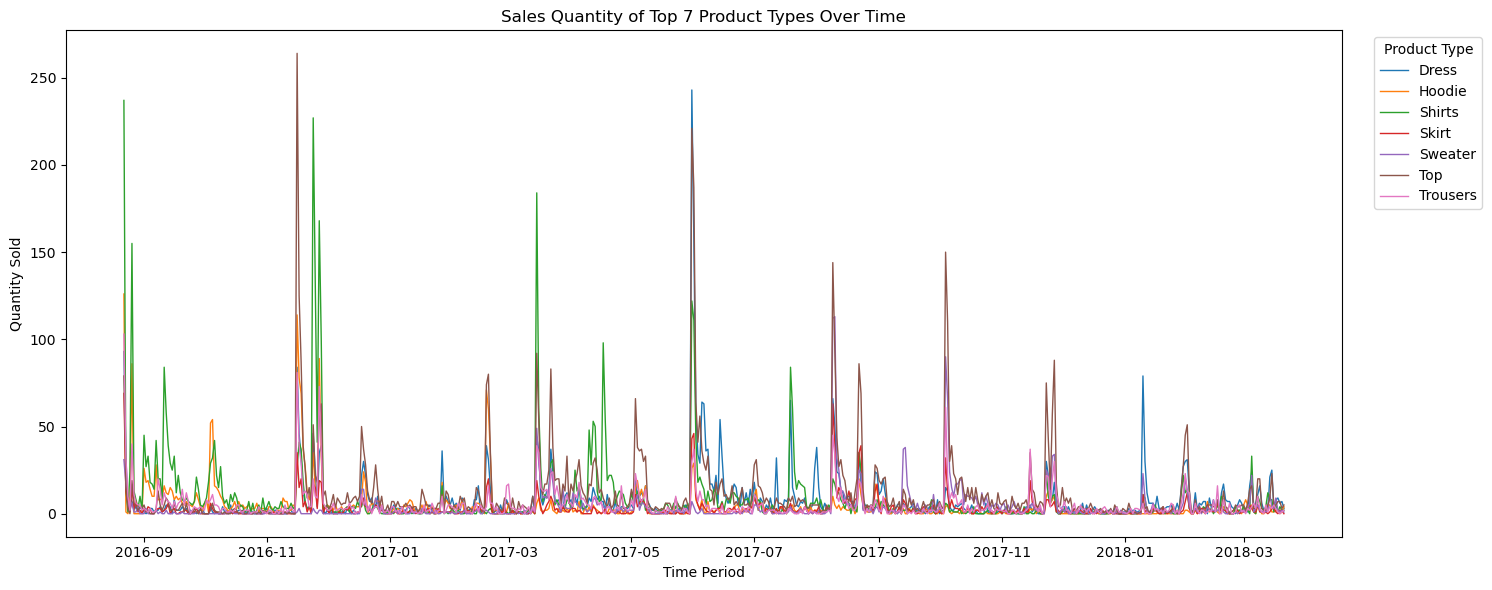

In [110]:
# ============================================================
# Visualization 1: Daily Sales Quantity of Top 7 Product Types
# 类似老师示例：看整个时间区间里的销量波动
# ============================================================

top_7_daily = (
    product_sales[
        product_sales["product_type"].isin(top_7_types)
    ]
    .groupby(["order_date", "product_type"], as_index=False)
    .agg(sales_quantity=("quantity", "sum"))
)

top_7_daily_pivot = (
    top_7_daily
    .pivot(
        index="order_date",
        columns="product_type",
        values="sales_quantity"
    )
    .fillna(0)
)

plt.figure(figsize=(15, 6))

for product_type in top_7_daily_pivot.columns:
    plt.plot(
        top_7_daily_pivot.index,
        top_7_daily_pivot[product_type],
        linewidth=1,
        label=product_type
    )

plt.title("Sales Quantity of Top 7 Product Types Over Time")
plt.xlabel("Time Period")
plt.ylabel("Quantity Sold")
plt.legend(
    title="Product Type",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
plt.tight_layout()
plt.show()


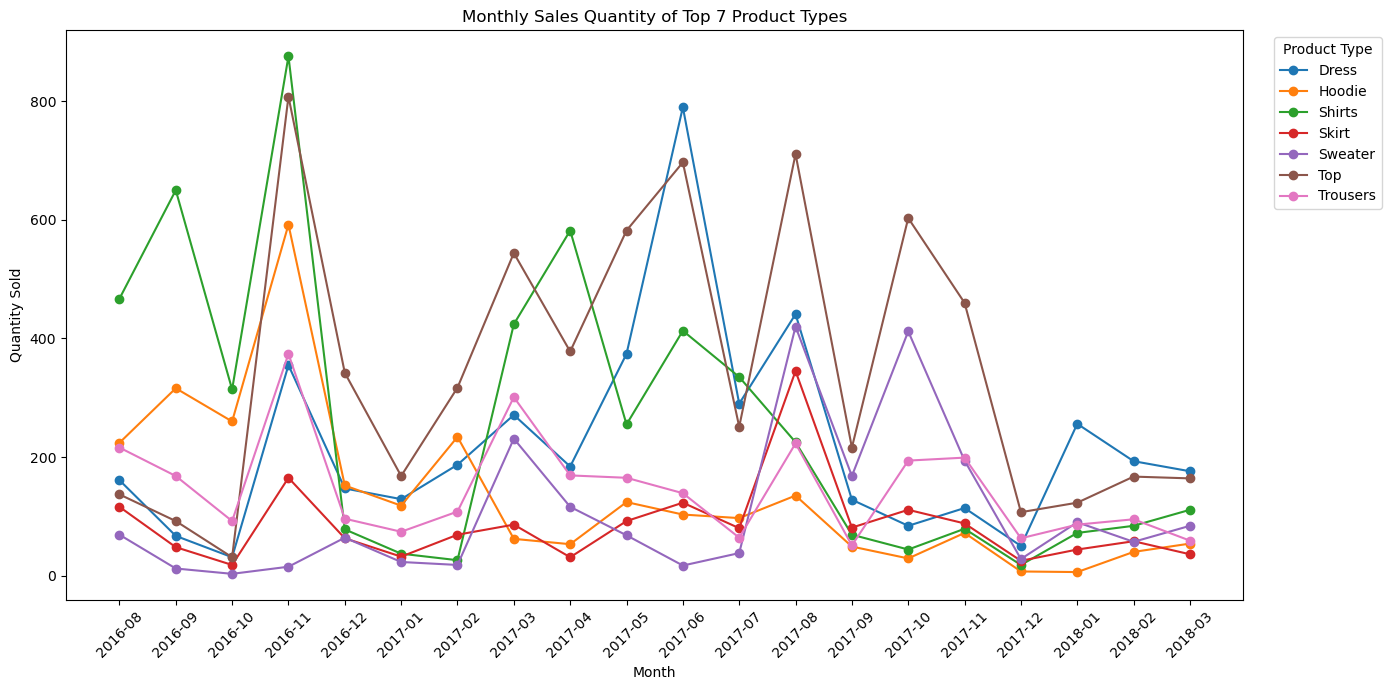

In [111]:
# ============================================================
# Visualization 2: Monthly Sales Quantity of Top 7 Product Types
# 月度汇总更容易看出季节性趋势
# ============================================================

top_7_monthly = (
    product_sales[
        product_sales["product_type"].isin(top_7_types)
    ]
    .groupby(["order_month", "product_type"], as_index=False)
    .agg(sales_quantity=("quantity", "sum"))
)

top_7_monthly_pivot = (
    top_7_monthly
    .pivot(
        index="order_month",
        columns="product_type",
        values="sales_quantity"
    )
    .fillna(0)
)

plt.figure(figsize=(14, 7))

for product_type in top_7_monthly_pivot.columns:
    plt.plot(
        top_7_monthly_pivot.index.astype(str),
        top_7_monthly_pivot[product_type],
        marker="o",
        linewidth=1.5,
        label=product_type
    )

plt.title("Monthly Sales Quantity of Top 7 Product Types")
plt.xlabel("Month")
plt.ylabel("Quantity Sold")
plt.xticks(rotation=45)
plt.legend(
    title="Product Type",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
plt.tight_layout()
plt.show()


,order_date,total_orders,discount_orders,no_discount_orders,discount_percentage,discount_quantity,no_discount_quantity
0,2016-08-22,778,1,777,0.001285,14,1383
1,2016-08-23,179,0,179,0.000000,0,275
2,2016-08-24,44,0,44,0.000000,0,73
3,2016-08-25,59,0,59,0.000000,0,78
4,2016-08-26,305,0,305,0.000000,0,496


,discount_quantity,no_discount_quantity,discount_orders,no_discount_orders,total_orders,discount_percentage
discount_quantity,1.000000,0.325446,0.951477,0.274306,0.644201,0.348159
no_discount_quantity,0.325446,1.000000,0.261068,0.987951,0.904241,-0.209612
discount_orders,0.951477,0.261068,1.000000,0.230886,0.631295,0.382307
no_discount_orders,0.274306,0.987951,0.230886,1.000000,0.900346,-0.238005
total_orders,0.644201,0.904241,0.631295,0.900346,1.000000,-0.018718
discount_percentage,0.348159,-0.209612,0.382307,-0.238005,-0.018718,1.000000


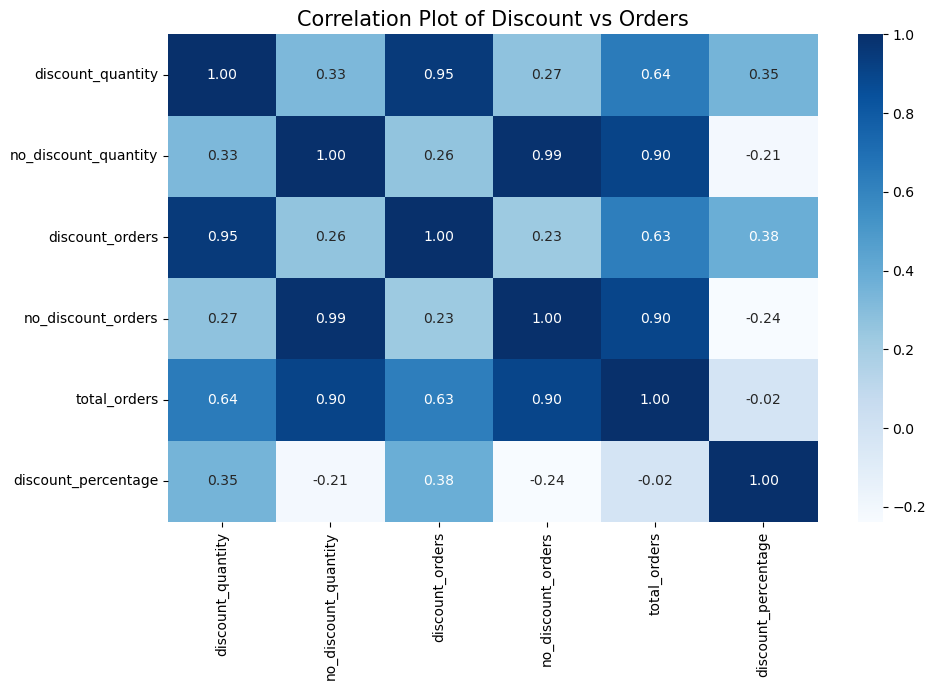

Discount % vs Total Orders: -0.019
Discount Quantity vs Total Orders: 0.644
Discount Orders vs Total Orders: 0.631


In [112]:
# ============================================================
# Discount vs Orders Correlation Analysis====================================================
# Same structure as instructor example
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ------------------------------------------------------------
# 1. Prepare order-level discount flags
# ------------------------------------------------------------

discount_flag = orders_analysis[
    [
        "order_id",
        "order_date",
        "total_discounts",
        "is_valid_sales_order"
    ]
].copy()

# Use only valid sales orders
discount_flag = discount_flag[
    discount_flag["is_valid_sales_order"]
].copy()

# Whether an order used a discount
discount_flag["has_discount"] = (
    discount_flag["total_discounts"] > 0
)

# ------------------------------------------------------------
# 2. Merge discount flag to order-item level
#    so we can calculate product quantities
# ------------------------------------------------------------

discount_items = orders_items_clean.merge(
    discount_flag[
        [
            "order_id",
            "order_date",
            "has_discount"
        ]
    ],
    on="order_id",
    how="inner"
)

# ------------------------------------------------------------
# 3. Daily discounted vs non-discounted product quantities
# ------------------------------------------------------------

daily_discount_quantity = (
    discount_items
    .assign(
        discount_quantity=np.where(
            discount_items["has_discount"],
            discount_items["quantity"],
            0
        ),
        no_discount_quantity=np.where(
            ~discount_items["has_discount"],
            discount_items["quantity"],
            0
        )
    )
    .groupby("order_date", as_index=False)
    .agg(
        discount_quantity=("discount_quantity", "sum"),
        no_discount_quantity=("no_discount_quantity", "sum")
    )
)

# ------------------------------------------------------------
# 4. Daily discounted vs non-discounted order counts
# ------------------------------------------------------------

daily_discount_orders = (
    discount_flag
    .groupby("order_date", as_index=False)
    .agg(
        total_orders=("order_id", "nunique"),
        discount_orders=("has_discount", "sum")
    )
)

daily_discount_orders["no_discount_orders"] = (
    daily_discount_orders["total_orders"]
    - daily_discount_orders["discount_orders"]
)

daily_discount_orders["discount_percentage"] = np.where(
    daily_discount_orders["total_orders"] > 0,
    daily_discount_orders["discount_orders"]
    / daily_discount_orders["total_orders"],
    0
)

# ------------------------------------------------------------
# 5. Combine quantity and order metrics
# ------------------------------------------------------------

discount_corr_data = daily_discount_orders.merge(
    daily_discount_quantity,
    on="order_date",
    how="inner",
    validate="one_to_one"
)

display(discount_corr_data.head())

# ------------------------------------------------------------
# 6. Correlation matrix
# ------------------------------------------------------------

teacher_corr_columns = [
    "discount_quantity",
    "no_discount_quantity",
    "discount_orders",
    "no_discount_orders",
    "total_orders",
    "discount_percentage"
]

discount_corr_matrix_teacher = (
    discount_corr_data[
        teacher_corr_columns
    ]
    .corr()
)

display(discount_corr_matrix_teacher)

# ------------------------------------------------------------
# 7. Heatmap
# ------------------------------------------------------------

plt.figure(figsize=(10, 7))

sns.heatmap(
    discount_corr_matrix_teacher,
    annot=True,
    fmt=".2f",
    cmap="Blues"
)

plt.title(
    "Correlation Plot of Discount vs Orders",
    fontsize=15
)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 8. Key correlations for easier interpretation
# ------------------------------------------------------------

print(
    "Discount % vs Total Orders:",
    round(
        discount_corr_matrix_teacher.loc[
            "discount_percentage",
            "total_orders"
        ],
        3
    )
)

print(
    "Discount Quantity vs Total Orders:",
    round(
        discount_corr_matrix_teacher.loc[
            "discount_quantity",
            "total_orders"
        ],
        3
    )
)

print(
    "Discount Orders vs Total Orders:",
    round(
        discount_corr_matrix_teacher.loc[
            "discount_orders",
            "total_orders"
        ],
        3
    )
)


In [113]:
# ============================================================
# EXPORT KEY ANALYSIS TABLES ONLY
# ============================================================

import os

EXPORT_DIR = "../data/processed"
os.makedirs(EXPORT_DIR, exist_ok=True)

# 1. Order-level analysis
orders_analysis.to_csv(
    f"{EXPORT_DIR}/orders_analysis.csv",
    index=False,
    encoding="utf-8-sig"
)

# 2. Traffic + order daily table
conversion_period.to_csv(
    f"{EXPORT_DIR}/traffic_orders_daily.csv",
    index=False,
    encoding="utf-8-sig"
)

# 3. Final customer table:
# CLV + RFM + K-Means cluster + K-Means business segment
customer_analysis.to_csv(
    f"{EXPORT_DIR}/customer_analysis.csv",
    index=False,
    encoding="utf-8-sig"
)

# 4. Product sales analysis
if "product_sales" in globals():
    product_sales.to_csv(
        f"{EXPORT_DIR}/product_sales.csv",
        index=False,
        encoding="utf-8-sig"
    )

# 5. Clean product master
products_clean.to_csv(
    f"{EXPORT_DIR}/products_clean.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Key analysis tables exported successfully!")
print("Saved to:", os.path.abspath(EXPORT_DIR))
print()
print("Files:")
print("1. orders_analysis.csv")
print("2. traffic_orders_daily.csv")
print("3. customer_analysis.csv")
print("4. product_sales.csv")
print("5. products_clean.csv")


Key analysis tables exported successfully!
Saved to: C:\Users\heche\00000-project-2026\003_ecommerce_business_analysis\data\processed

Files:
1. orders_analysis.csv
2. traffic_orders_daily.csv
3. customer_analysis.csv
4. product_sales.csv
5. products_clean.csv


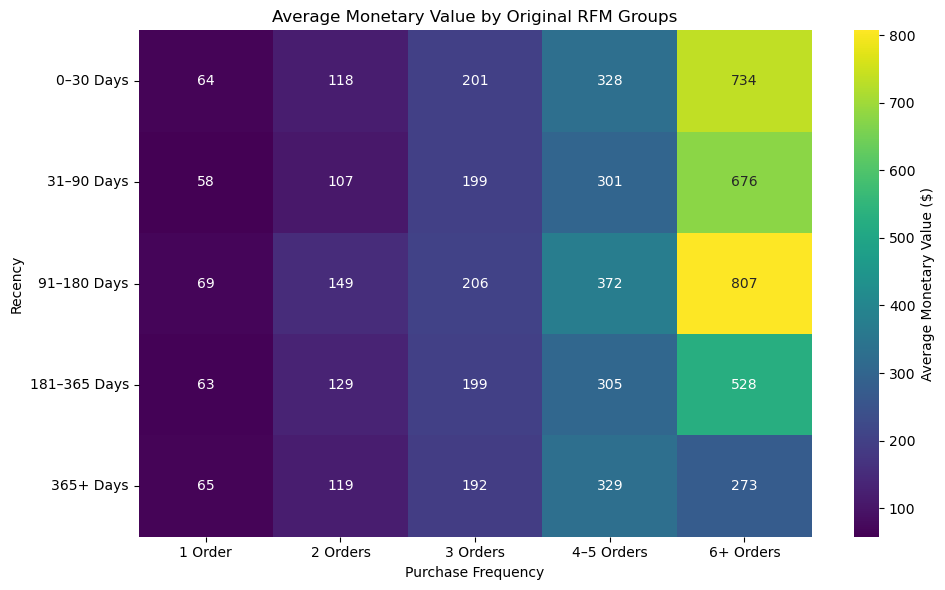

In [114]:
# ============================================================
# Heatmap Using Original RFM Values
# ============================================================

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 使用原始 RFM 数据
rfm_heatmap_data = rfm[
    ["recency", "frequency", "monetary"]
].copy()

# Recency 按实际天数分组
rfm_heatmap_data["Recency Group"] = pd.cut(
    rfm_heatmap_data["recency"],
    bins=[0, 30, 90, 180, 365, float("inf")],
    labels=[
        "0–30 Days",
        "31–90 Days",
        "91–180 Days",
        "181–365 Days",
        "365+ Days"
    ],
    include_lowest=True
)

# Frequency 按原始购买次数分组
rfm_heatmap_data["Frequency Group"] = pd.cut(
    rfm_heatmap_data["frequency"],
    bins=[0, 1, 2, 3, 5, float("inf")],
    labels=[
        "1 Order",
        "2 Orders",
        "3 Orders",
        "4–5 Orders",
        "6+ Orders"
    ],
    include_lowest=True
)

# 每个组合计算原始 Monetary 的平均值
rfm_heatmap = rfm_heatmap_data.pivot_table(
    index="Recency Group",
    columns="Frequency Group",
    values="monetary",
    aggfunc="mean",
    observed=False
)

# 画图
plt.figure(figsize=(10, 6))

sns.heatmap(
    rfm_heatmap,
    annot=True,
    fmt=".0f",
    cmap="viridis",
    cbar_kws={"label": "Average Monetary Value ($)"}
)

plt.title("Average Monetary Value by Original RFM Groups")
plt.xlabel("Purchase Frequency")
plt.ylabel("Recency")

plt.tight_layout()
plt.show()